## **Machine Learning at scale practicals**

## **Practical 1**

### **1. Download the dataset**

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import csv
import random
from numba import njit, prange
from itertools import product
import pandas as pd
import seaborn as sns
import pickle
import gc

### **2. Data Download and extraction**

In [ ]:
URL = "https://files.grouplens.org/datasets/movielens/ml-32m.zip"
ZIP_FILE = "ml-32m.zip"
EXTRACT_FOLDER = "ml-32m"
RATINGS_PATH = "ml-32m/ml-32m/ratings.csv"

print(f"Downloading {URL}...")
!wget -q {URL}

if os.path.exists(ZIP_FILE):
    print(f"Extracting {ZIP_FILE}...")
    !unzip -q -o {ZIP_FILE} -d {EXTRACT_FOLDER}
    print("Extraction complete.\n")
else:
    raise FileNotFoundError(f"Download failed: {ZIP_FILE} not found")

Extracting ml-32m.zip...
Extraction complete.



### **3. Build Indices**
Create bidirectional indices for (a) users and (b) movies


In [ ]:
# Load data from csv to numpy
print("Loading ratings data...")
ratings = np.loadtxt(RATINGS_PATH, delimiter=",", skiprows=1, usecols=(0, 1, 2))

user_ids = ratings[:, 0].astype(int)
movie_ids = ratings[:, 1].astype(int)
rating_values = ratings[:, 2]

print(f"Loaded {len(ratings):,} ratings\n")

Loading ratings data...
Loaded 32,000,204 ratings



In [ ]:
def build_indices(ratings):
    print("Building index structures...")

    # Initialize data structures
    userid_to_idx = {}
    idx_to_userid = []
    data_by_user = []

    movieid_to_idx = {}
    idx_to_movieid = []
    data_by_movie = []

    # Build indices by iterating through all ratings
    for user_id, movie_id, rating in ratings:
        user_id = int(user_id)
        movie_id = int(movie_id)

        # Add user if not seen before
        if user_id not in userid_to_idx:
            userid_to_idx[user_id] = len(idx_to_userid)
            idx_to_userid.append(user_id)
            data_by_user.append([])

        # Add movie if not seen before
        if movie_id not in movieid_to_idx:
            movieid_to_idx[movie_id] = len(idx_to_movieid)
            idx_to_movieid.append(movie_id)
            data_by_movie.append([])

        # Store rating in both indices
        user_idx = userid_to_idx[user_id]
        movie_idx = movieid_to_idx[movie_id]

        data_by_user[user_idx].append((movie_idx, rating))
        data_by_movie[movie_idx].append((user_idx, rating))

    print(f"Indexed {len(idx_to_userid):,} users and {len(idx_to_movieid):,} movies\n")

    return (userid_to_idx, idx_to_userid, data_by_user), (movieid_to_idx, idx_to_movieid, data_by_movie)

In [ ]:
user_data, movie_data = build_indices(ratings)

userid_to_idx, idx_to_userid, data_by_user = user_data
movieid_to_idx, idx_to_movieid, data_by_movie = movie_data

Building index structures...
Indexed 200,948 users and 84,432 movies



In [ ]:
# Simple interfaces to query the indexed data
def get_user_rating_count(user_id):
    """Return number of movies rated by a user"""
    return len(data_by_user[userid_to_idx[user_id]])

def get_movie_rating_count(movie_id):
    """Return number of users who rated a movie"""
    return len(data_by_movie[movieid_to_idx[movie_id]])

In [ ]:
user_13_ratings = get_user_rating_count(13)
print(f"User 13 rated {user_13_ratings:,} movies")

movie_13_ratings = get_movie_rating_count(13)
print(f"Movie 13 was rated by {movie_13_ratings:,} users")

User 13 rated 65 movies
Movie 13 was rated by 2,107 users


### **4. Exploring the dataset**

**Movies Statistics**

In [ ]:
# Load Movie Titles
movie_titles = {}
with open('ml-32m/ml-32m/movies.csv', encoding='utf-8') as movies:
    reader = csv.reader(movies)
    next(reader)
    for row in reader:
        movie_titles[int(row[0])] = row[1]

In [ ]:
movie_stats = []
for movie_idx, ratings_list in enumerate(data_by_movie):
    count = len(ratings_list)
    if count > 0:
        total_rating = sum(r for u, r in ratings_list)
        mean_rating = total_rating / count
    else:
        mean_rating = 0

    raw_id = idx_to_movieid[movie_idx]
    title = movie_titles.get(raw_id, f"Movie {raw_id}")

    movie_stats.append({
        "title": title,
        "count": count,
        "mean": mean_rating
    })

sorted_by_popularity = sorted(movie_stats, key=lambda x: x['count'], reverse=True)
top_20 = sorted_by_popularity[:10]

top_titles = [m['title'] for m in top_20]
top_counts = [m['count'] for m in top_20]

item_means = [m['mean'] for m in movie_stats if m['count'] > 0]

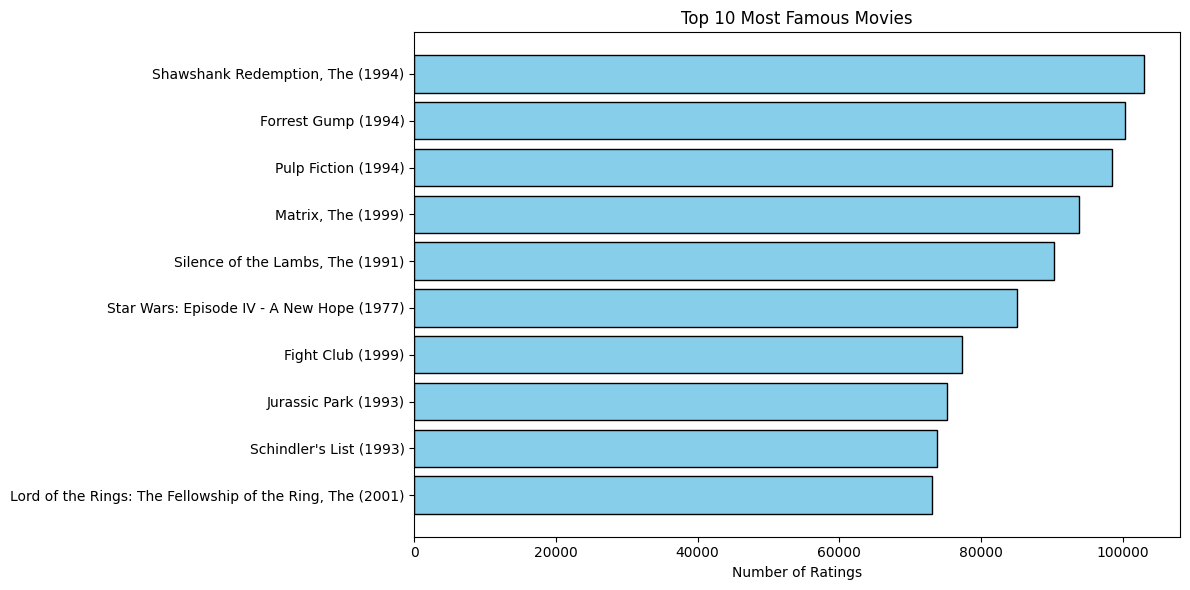

In [ ]:
# Top 10 Most Famous Movies
plt.figure(figsize=(12, 6))
y_pos = np.arange(len(top_titles))
plt.barh(y_pos, top_counts, align='center', color='skyblue', edgecolor='black')
plt.yticks(y_pos, top_titles)
plt.gca().invert_yaxis()
plt.xlabel('Number of Ratings')
plt.title('Top 10 Most Famous Movies')
plt.savefig('most_famous_movies.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

This visualisation highlights the blackbusters in the dataset. Probably the high number of ratings is due to the age of the movies.

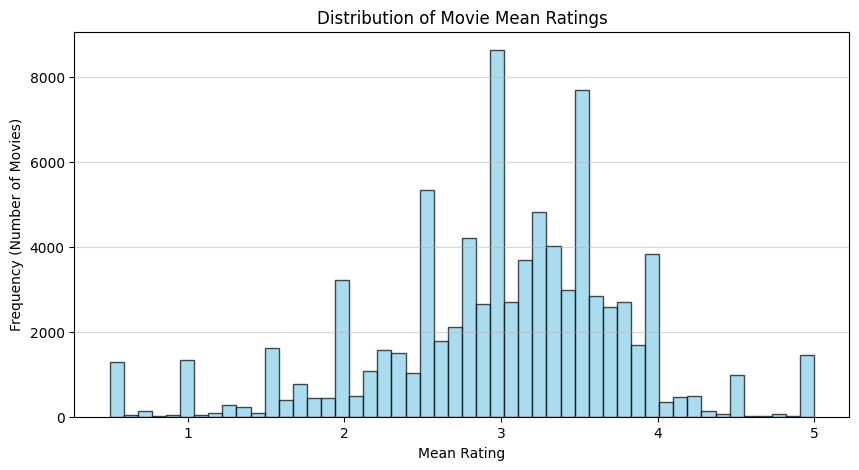

In [ ]:
# Distribution of Item Mean Ratings
plt.figure(figsize=(10, 5))
plt.hist(item_means, bins=50, color='skyblue', alpha=0.7, edgecolor='black')
plt.title('Distribution of Movie Mean Ratings')
plt.xlabel('Mean Rating')
plt.ylabel('Frequency (Number of Movies)')
plt.grid(axis='y', alpha=0.5)
plt.savefig('movie_mean_ratings.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

This distribution has notable peaks at whole star and half star intervals. The overall trend leans slightly toward the positive side, with an average movie rating between 3.0 and 3.5.

**User Statistics**

In [ ]:
user_means = []
for user_idx, ratings_list in enumerate(data_by_user):
    count = len(ratings_list)
    if count > 0:
        total_rating = sum(r for m, r in ratings_list)
        mean_val = total_rating / count
        user_means.append(mean_val)

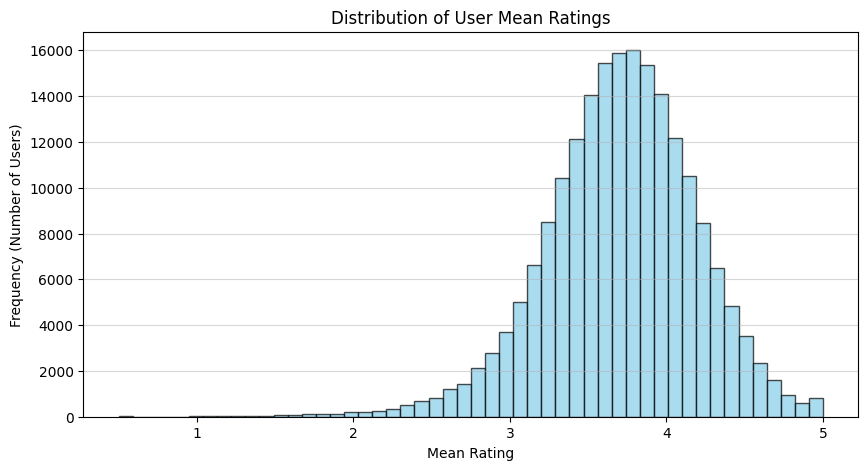

In [ ]:
# Distribution of User Mean Ratings
plt.figure(figsize=(10, 5))
plt.hist(user_means, bins=50, color='skyblue', alpha=0.7, edgecolor='black')
plt.title('Distribution of User Mean Ratings')
plt.xlabel('Mean Rating')
plt.ylabel('Frequency (Number of Users)')
plt.grid(axis='y', alpha=0.5)
plt.savefig('user_mean_ratings.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

This histogram represents the average behavior of users in terms of rating. The distribution clearly follows a normal distribution centered around an average of approximately 3.7

### **5. Ratings distribution analysis**

Plotting rating distribution...


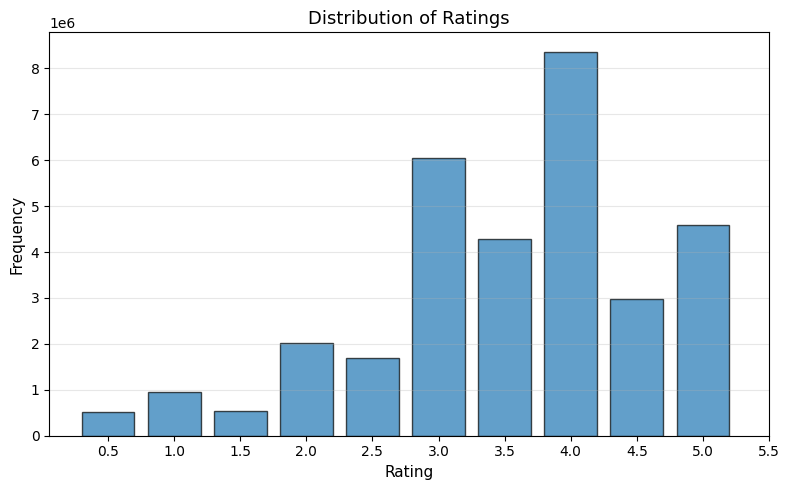

In [ ]:
print("Plotting rating distribution...")

fig, ax = plt.subplots(figsize=(8, 5))
rating_bins = [0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5]

ax.hist(rating_values, bins=rating_bins, edgecolor="black", rwidth=0.8, alpha=0.7, align='left')
ax.set_xlabel("Rating", fontsize=11)
ax.set_ylabel("Frequency", fontsize=11)
ax.set_title("Distribution of Ratings", fontsize=13)
ax.set_xticks(rating_bins)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('ratings_distribution.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

This user ratings show a positive skew, clustering around 3.5-4.5 stars because people tend to watch and rate movies they expect to enjoy.

The rating patterns reveal user preferences for whole numbers over half-stars,and scarcity of very low ratings since viewers often abandon disliked movies rather than rating them poorly.


### **6. Power law analysis**

Analyzing degree distributions for power law behavior...


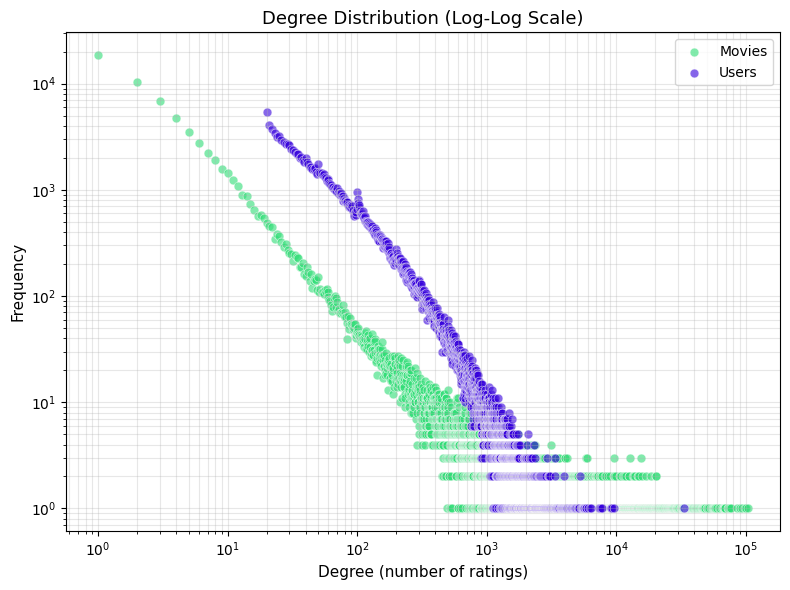

Summary statistics

User degrees - Min: 20, Max: 33,332, Mean: 159.2
Movie degrees - Min: 1, Max: 102,929, Mean: 379.0

The user degree minimum of 20 is due to dataset filtering.

This truncation affects the power law distribution shape.


In [ ]:
print("Analyzing degree distributions for power law behavior...")

# Extract degree (number of ratings) for each user and movie
user_degrees = [len(ratings_list) for ratings_list in data_by_user]
movie_degrees = [len(ratings_list) for ratings_list in data_by_movie]

# Create log-log scatter plot
fig, ax = plt.subplots(figsize=(8, 6))

for degrees, color, label in [(movie_degrees, '#2edd75', 'Movies'),
                               (user_degrees, '#3500dc', 'Users')]:
    # Get unique degree values and their frequencies
    unique_degrees, counts = np.unique(degrees, return_counts=True)
    ax.scatter(unique_degrees, counts, c=color, s=40, alpha=0.6,
               label=label, edgecolors='white', linewidths=0.5)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Degree (number of ratings)', fontsize=11)
ax.set_ylabel('Frequency', fontsize=11)
ax.set_title('Degree Distribution (Log-Log Scale)', fontsize=13)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.savefig('power_law_distribution.pdf', bbox_inches='tight', dpi=300)
plt.show()

# Summary statistics
print("Summary statistics")
print(f"\nUser degrees - Min: {min(user_degrees)}, Max: {max(user_degrees):,}, "
      f"Mean: {np.mean(user_degrees):.1f}")
print(f"Movie degrees - Min: {min(movie_degrees)}, Max: {max(movie_degrees):,}, "
      f"Mean: {np.mean(movie_degrees):.1f}")
print("\nThe user degree minimum of 20 is due to dataset filtering.")
print("\nThis truncation affects the power law distribution shape.")


This is actually a power law distribution as it describe a pattern where a few entities have extremely high values while most have very low values, appearing as a straight line on a log-log plot.

In movie rating data, we notice a few blockbuster films receive millions of ratings while most independent films get very few, and similarly a few super-active users rates thousands of movies while most users rate only occasionally.

The MovieLens32M dataset is artificially truncated because it excludes all users who rated fewer than 20 movies, cutting off the left tail of the natural distribution.
This truncation distorts the visual pattern on log-log plots, creating a flat or broken line on the left side instead of the expected smooth power law curve.

On the other hand, the movie rating distribution appears to follow a scale-free pattern, whereas the user rating distribution deviates sligthly from this pattern.

## **Practical 2**

### **1. Download a smaller dataset**

In [ ]:
# URL of the dataset
url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
zip_file2 = "ml-latest-small.zip"
extract_folder2 = "ml-latest-small"

print(f"Starting download of {url}...")
!wget -q $url

print("Download complete.")
if os.path.exists(zip_file2):
    print(f"Successfully downloaded {zip_file2}.")
    print(f"Unzipping {zip_file2}...")
    !unzip -o $zip_file2 -d $extract_folder2

    print(f"Successfully unzipped to '{extract_folder2}' folder.")
    print(f"\nContents of {extract_folder2}:")
    !ls -l $extract_folder2
else:
    print(f"Error: {zip_file2} was not downloaded.")

Starting download of https://files.grouplens.org/datasets/movielens/ml-latest-small.zip...
Download complete.
Successfully downloaded ml-latest-small.zip.
Unzipping ml-latest-small.zip...
Archive:  ml-latest-small.zip
   creating: ml-latest-small/ml-latest-small/
  inflating: ml-latest-small/ml-latest-small/links.csv  
  inflating: ml-latest-small/ml-latest-small/tags.csv  
  inflating: ml-latest-small/ml-latest-small/ratings.csv  
  inflating: ml-latest-small/ml-latest-small/README.txt  
  inflating: ml-latest-small/ml-latest-small/movies.csv  
Successfully unzipped to 'ml-latest-small' folder.

Contents of ml-latest-small:
total 4
drwxr-xr-x 2 root root 4096 Sep 26  2018 ml-latest-small


### **2. Build Indices**

In [ ]:
# Load data
print("Loading ratings...")
ratings = np.loadtxt(
    "ml-latest-small/ml-latest-small/ratings.csv",
    delimiter=",",
    skiprows=1,
    usecols=(0, 1, 2)
)

users = ratings[:, 0].astype(int)
movies = ratings[:, 1].astype(int)
rating = ratings[:, 2].astype(float)

print(f"Loaded {len(ratings):,} ratings")

Loading ratings...
Loaded 100,836 ratings


In [ ]:
user_data, movie_data = build_indices(ratings)

userid_to_idx, idx_to_userid, data_by_user = user_data
movieid_to_idx, idx_to_movieid, data_by_movie = movie_data

Building index structures...
Indexed 610 users and 9,724 movies



In [ ]:
user_17_ratings = get_user_rating_count(17)
print(f"User 17 rated {user_17_ratings:,} movies")

movie_17_ratings = get_movie_rating_count(17)
print(f"Movie 17 was rated by {movie_17_ratings:,} users")

User 17 rated 105 movies
Movie 17 was rated by 67 users


### **3. Split dataset into train and test datasets**
Split the ratings data into training (90%) and test (10%) sets

In [ ]:
def split_train_test(data_by_user, number_of_users, number_of_movies,
                     train_ratio=0.9, random_seed=42, verbose=True):
    """
    Split rating data into training and test sets
    Parameters
    data_by_user : list of lists
    number_of_users : int
    number_of_movies : int
    train_ratio : float
    random_seed : int, Random seed for reproducibility
    verbose : bool

    Returns
    tuple of (data_by_user_train, data_by_user_test,
              data_by_movie_train, data_by_movie_test)
    """

    # Input validation
    if not 0.0 < train_ratio < 1.0:
        raise ValueError(f"train_ratio must be between 0 and 1, got {train_ratio}")

    if len(data_by_user) != number_of_users:
        raise ValueError(f"data_by_user length ({len(data_by_user)}) "
                        f"doesn't match number_of_users ({number_of_users})")

    random.seed(random_seed)

    if verbose:
        print("Splitting data into train and test sets...")
        print(f"({train_ratio*100:.0f}% train, "
              f"{(1-train_ratio)*100:.0f}% test)")

    # Initialize empty structures
    data_by_user_train = [[] for _ in range(number_of_users)]
    data_by_user_test = [[] for _ in range(number_of_users)]
    data_by_movie_train = [[] for _ in range(number_of_movies)]
    data_by_movie_test = [[] for _ in range(number_of_movies)]

    # Split each user's ratings
    for user_idx in range(number_of_users):
        user_ratings = data_by_user[user_idx].copy()

        random.shuffle(user_ratings)
        split_point = int(train_ratio * len(user_ratings))

        train_ratings = user_ratings[:split_point]
        test_ratings = user_ratings[split_point:]

        data_by_user_train[user_idx] = train_ratings
        data_by_user_test[user_idx] = test_ratings

        # Populate movie-centric structures
        for movie_idx, rating in train_ratings:
            data_by_movie_train[movie_idx].append((user_idx, rating))

        for movie_idx, rating in test_ratings:
            data_by_movie_test[movie_idx].append((user_idx, rating))

    # Calculate and display statistics
    if verbose:
        # Verify split
        total_ratings = sum(len(ratings) for ratings in data_by_user)
        train_count = sum(len(ratings) for ratings in data_by_user_train)
        test_count = sum(len(ratings) for ratings in data_by_user_test)

        print(f"Total ratings: {total_ratings:,}")
        print(f"Train: {train_count:,} ({train_count/total_ratings*100:.1f}%)")
        print(f"Test: {test_count:,} ({test_count/total_ratings*100:.1f}%)\n")

    return (data_by_user_train, data_by_user_test,
            data_by_movie_train, data_by_movie_test)

In [ ]:
number_of_users = len(idx_to_userid)
number_of_movies = len(idx_to_movieid)

data_by_user_train, data_by_user_test, data_by_movie_train, data_by_movie_test = \
    split_train_test(data_by_user, number_of_users, number_of_movies)

Splitting data into train and test sets...
(90% train, 10% test)
Total ratings: 100,836
Train: 90,478 (89.7%)
Test: 10,358 (10.3%)



### **4. Build model for bias optimization**

Model Initialization

Bias model predict ratings as: $\hat{r}_{mn} = b_m^u + b_n^i$


In [ ]:
M = number_of_users
N = number_of_movies

# Hyperparameters
lambd = 0.1
gamma = 0.1
num_iters = 30

# Initialize biases to zero
user_biases = np.zeros(M)
item_biases = np.zeros(N)

# Tracking metrics
loss_history = []
train_rmse_history = []
test_rmse_history = []

print("Model Configuration:")
print(f"  Users: {M:,}, Items: {N:,}")
print(f"  Learning rate (λ): {lambd}")
print(f"  Regularization (γ): {gamma}")
print(f"  Iterations: {num_iters}\n")

Model Configuration:
  Users: 610, Items: 9,724
  Learning rate (λ): 0.1
  Regularization (γ): 0.1
  Iterations: 30



Alternating least square training

Find maximum likelihood estimates for user and item biases.

#### Loss Function:

$$\mathcal{L} = \frac{λ}{2}\sum_{mn} (r_{mn} - b_m^{u} - b_n^{i})^2 +\frac{\gamma}{2} \left(\sum_m b_m^{u2} + \sum_n b_n^{i2}\right)$$

#### ALS update rules:
(fix $b_i$, update $b_u$):

$$b_m^u = \frac{\lambda \sum_{n \in Ω(m)} (r_{mn} - b_n^i)}{\lambda|Ω(m)| + \gamma}$$
(fix $b_u$, update $b_i$):

$$b_n^i = \frac{\lambda \sum_{m \in Ω(n)} (r_{mn} - b_m^u)}{\lambda|Ω(n)| + \gamma}$$


#### RMSE:

$$\text{RMSE} = \sqrt{\frac{\sum_{mn} (r_{mn} - \hat{r}_{mn})^2}{n_{~of~ratings}}}$$

In [ ]:
def prepare_flat_data(data_by_user, data_by_movie, M, N):
    """
    Flattens list-of-list data into contiguous Numpy arrays for Numba/C-speed processing.

    Returns:
    - user_vals: All rating values sorted by user
    - user_idx:  All movie indices sorted by user
    - user_map:  (M, 2) array where row u is [start_index, end_index]
    - item_vals: All rating values sorted by movie
    - item_idx:  All user indices sorted by movie
    - item_map:  (N, 2) array where row i is [start_index, end_index]
    """

    # PROCESS USERS
    # Calculate total size to pre-allocate arrays
    total_user_ratings = sum(len(u) for u in data_by_user)

    user_vals = np.zeros(total_user_ratings, dtype=np.float64)
    user_idx = np.zeros(total_user_ratings, dtype=np.int32)
    user_map = np.zeros((M, 2), dtype=np.int32)

    current_ptr = 0
    for u in range(M):
        ratings = data_by_user[u]
        count = len(ratings)

        user_map[u, 0] = current_ptr
        user_map[u, 1] = current_ptr + count

        for i, (item_id, rating) in enumerate(ratings):
            user_idx[current_ptr + i] = item_id
            user_vals[current_ptr + i] = rating

        current_ptr += count

    # PROCESS ITEMS
    total_item_ratings = sum(len(i) for i in data_by_movie)

    item_vals = np.zeros(total_item_ratings, dtype=np.float64)
    item_idx = np.zeros(total_item_ratings, dtype=np.int32)
    item_map = np.zeros((N, 2), dtype=np.int32)

    current_ptr = 0
    for i in range(N):
        ratings = data_by_movie[i]
        count = len(ratings)

        item_map[i, 0] = current_ptr
        item_map[i, 1] = current_ptr + count

        for j, (user_id, rating) in enumerate(ratings):
            item_idx[current_ptr + j] = user_id
            item_vals[current_ptr + j] = rating

        current_ptr += count

    return user_vals, user_idx, user_map, item_vals, item_idx, item_map

In [ ]:
@njit(parallel=True)
def update_user_biases(user_vals, user_idx, user_map,
                              user_biases, item_biases,
                              lambd, gamma):
    """
    Update all user biases using alternating least squares.
    """
    M = user_map.shape[0]

    for user_id in prange(M):
        start_idx = user_map[user_id, 0]
        end_idx = user_map[user_id, 1]

        numerator = 0.0
        denominator = 0.0

        for ptr in range(start_idx, end_idx):
            movie_id = user_idx[ptr]
            rating = user_vals[ptr]

            residual = rating - item_biases[movie_id]
            numerator += lambd * residual
            denominator += lambd

        if denominator > 0:
            user_biases[user_id] = numerator / (denominator + gamma)

In [ ]:
@njit(parallel=True)
def update_item_biases(item_vals, item_idx, item_map,
                              user_biases, item_biases,
                              lambd, gamma):
    """
    Update all item biases using alternating least squares (Numba-optimized).
    """
    N = item_map.shape[0]

    for movie_id in prange(N):
        start_idx = item_map[movie_id, 0]
        end_idx = item_map[movie_id, 1]

        numerator = 0.0
        denominator = 0.0

        for ptr in range(start_idx, end_idx):
            user_id = item_idx[ptr]
            rating = item_vals[ptr]

            residual = rating - user_biases[user_id]
            numerator += lambd * residual
            denominator += lambd

        if denominator > 0:
            item_biases[movie_id] = numerator / (denominator + gamma)

In [ ]:
@njit
def evaluate_rmse(user_vals, user_idx, user_map,
                        user_biases, item_biases):
    """
    Calculate RMSE on a dataset (Numba-optimized).

    Returns
    tuple of (rmse, sse, count)
    """
    M = user_map.shape[0]
    sse = 0.0
    count = 0

    for user_id in range(M):
        start_idx = user_map[user_id, 0]
        end_idx = user_map[user_id, 1]

        for ptr in range(start_idx, end_idx):
            movie_id = user_idx[ptr]
            rating = user_vals[ptr]

            prediction = user_biases[user_id] + item_biases[movie_id]
            error = rating - prediction
            sse += error * error
            count += 1

    rmse = np.sqrt(sse / count) if count > 0 else np.inf
    return rmse, sse, count

In [ ]:
def train_bias_model(data_by_user_train, data_by_movie_train,
                           data_by_user_test, M, N,
                           lambd, gamma, num_iters,
                           verbose=True):
    """
    Train bias model using Numba-optimized ALS (10-100x faster).

    Parameters
    ----------
    data_by_user_train : list of lists
        Training data indexed by user
    data_by_movie_train : list of lists
        Training data indexed by movie
    data_by_user_test : list of lists
        Test data indexed by user
    M : int
        Number of users
    N : int
        Number of movies
    lambd : float, optional (default=0.1)
        Learning rate
    gamma : float, optional (default=0.1)
        Regularization strength
    num_iters : int, optional (default=30)
        Number of ALS iterations
    verbose : bool, optional (default=True)
        Print progress

    Returns
    -------
    dict with results
    """

    if verbose:
        print("Preparing flat data structures")

    # Flatten training data
    train_user_vals, train_user_idx, train_user_map, \
    train_item_vals, train_item_idx, train_item_map = \
        prepare_flat_data(data_by_user_train, data_by_movie_train, M, N)

    # Flatten test data
    test_user_vals, test_user_idx, test_user_map, _, _, _ = \
        prepare_flat_data(data_by_user_test, [[] for _ in range(N)], M, N)

    # Initialize biases
    user_biases = np.zeros(M, dtype=np.float64)
    item_biases = np.zeros(N, dtype=np.float64)

    # Track metrics
    loss_history = []
    train_rmse_history = []
    test_rmse_history = []

    if verbose:
        print("Starting Numba-Optimized ALS Training...")
        print("=" * 60)
        print(f"Parameters: λ={lambd}, γ={gamma}, iterations={num_iters}")
        print(f"Users: {M:,}, Movies: {N:,}")
        print()

    # Training loop
    for iteration in range(num_iters):

        # Update user biases
        update_user_biases(train_user_vals, train_user_idx, train_user_map,
                                 user_biases, item_biases, lambd, gamma)

        # Update item biases
        update_item_biases(train_item_vals, train_item_idx, train_item_map,
                                 user_biases, item_biases, lambd, gamma)

        # Evaluate on training set
        train_rmse, train_sse, train_count = evaluate_rmse(
            train_user_vals, train_user_idx, train_user_map,
            user_biases, item_biases
        )
        loss_history.append(train_sse)
        train_rmse_history.append(train_rmse)

        # Evaluate on test set
        test_rmse, test_sse, test_count = evaluate_rmse(
            test_user_vals, test_user_idx, test_user_map,
            user_biases, item_biases
        )
        test_rmse_history.append(test_rmse)

        if verbose:
            print(f"Iter {iteration+1:2d}/{num_iters}: "
                  f"Loss = {train_sse:,.0f}, "
                  f"Train RMSE = {train_rmse:.4f}, "
                  f"Test RMSE = {test_rmse:.4f}")

    if verbose:
        print("=" * 60)
        print("Training Complete!\n")
        print(f"Final Train RMSE: {train_rmse_history[-1]:.4f}")
        print(f"Final Test RMSE:  {test_rmse_history[-1]:.4f}")
        print(f"Generalization Gap: "
              f"{test_rmse_history[-1] - train_rmse_history[-1]:.4f}\n")

    return {
        'user_biases': user_biases,
        'item_biases': item_biases,
        'loss_history': loss_history,
        'train_rmse_history': train_rmse_history,
        'test_rmse_history': test_rmse_history
    }

In [ ]:
results = train_bias_model(
    data_by_user_train=data_by_user_train,
    data_by_movie_train=data_by_movie_train,
    data_by_user_test=data_by_user_test,
    M=number_of_users,
    N=number_of_movies,
    lambd=0.1,
    gamma=0.1,
    num_iters=30,
    verbose=True
)

# Extract results
user_biases = results['user_biases']
item_biases = results['item_biases']

Preparing flat data structures
Starting Numba-Optimized ALS Training...
Parameters: λ=0.1, γ=0.1, iterations=30
Users: 610, Movies: 9,724

Iter  1/30: Loss = 59,059, Train RMSE = 0.8079, Test RMSE = 0.8776
Iter  2/30: Loss = 57,071, Train RMSE = 0.7942, Test RMSE = 0.8658
Iter  3/30: Loss = 56,926, Train RMSE = 0.7932, Test RMSE = 0.8652
Iter  4/30: Loss = 56,899, Train RMSE = 0.7930, Test RMSE = 0.8651
Iter  5/30: Loss = 56,889, Train RMSE = 0.7929, Test RMSE = 0.8651
Iter  6/30: Loss = 56,885, Train RMSE = 0.7929, Test RMSE = 0.8651
Iter  7/30: Loss = 56,885, Train RMSE = 0.7929, Test RMSE = 0.8652
Iter  8/30: Loss = 56,886, Train RMSE = 0.7929, Test RMSE = 0.8653
Iter  9/30: Loss = 56,888, Train RMSE = 0.7929, Test RMSE = 0.8654
Iter 10/30: Loss = 56,892, Train RMSE = 0.7930, Test RMSE = 0.8655
Iter 11/30: Loss = 56,896, Train RMSE = 0.7930, Test RMSE = 0.8657
Iter 12/30: Loss = 56,901, Train RMSE = 0.7930, Test RMSE = 0.8658
Iter 13/30: Loss = 56,906, Train RMSE = 0.7931, Test RMSE

In [ ]:
# Make predictions for a specific user-movie pair
def predict_rating(user_idx, movie_idx, user_biases, item_biases):
    """Predict rating for a user-movie pair."""
    return user_biases[user_idx] + item_biases[movie_idx]

predict_rating_17 = predict_rating(17, 17, user_biases, item_biases)
print(f"Predicted rating for user 17 and movie 17: {predict_rating_17:.2f}")

Predicted rating for user 17 and movie 17: 3.42


### **5. Plot Loss, Training RMSE, and Test RMSE**

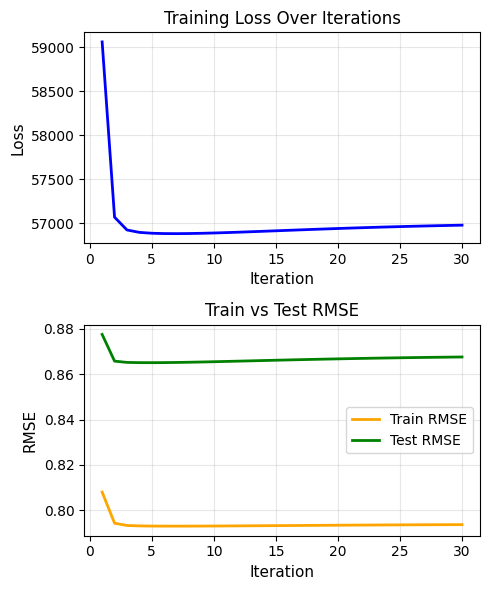

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(5, 6))

# Training Loss (Sum of Squared Errors)
ax1.plot(range(1, num_iters + 1), results['loss_history'][-num_iters:], 'b-', linewidth=2)
ax1.set_xlabel('Iteration', fontsize=11)
ax1.set_ylabel('Loss', fontsize=11)
ax1.set_title('Training Loss Over Iterations',
              fontsize=12)
ax1.grid(True, alpha=0.3)

# Train vs Test RMSE
ax2.plot(range(1, num_iters + 1), results['train_rmse_history'][-num_iters:],
         'orange', linewidth=2, label='Train RMSE')
ax2.plot(range(1, num_iters + 1), results['test_rmse_history'][-num_iters:],
         'green', linewidth=2, label='Test RMSE')
ax2.set_xlabel('Iteration', fontsize=11)
ax2.set_ylabel('RMSE', fontsize=11)
ax2.set_title('Train vs Test RMSE', fontsize=12)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('bias_model_training.pdf', dpi=300, bbox_inches='tight')
plt.show()

We observe the loss decreases monotonically during training.

The training RMSE converges to around $0.79$~$0.8$ for this simple bias model with $λ=0.1$ and $γ=0.1$.

The test RMSE converges to a value slightly higher than training RMSE ($0.86$~$0.87$), representing the generalization gap.

### Hyper parameter configuration

In [ ]:
def grid_search_hyperparameters(data_by_user_train, data_by_movie_train,
                                data_by_user_test, M, N,
                                lambda_values,
                                gamma_values,
                                iter_values,
                                verbose=True):
    """
    Perform grid search over hyperparameters to find best configuration.

    Returns
    dict with keys:
        'results': DataFrame with all configurations and their performance
        'best_config': dict with best hyperparameters
        'best_model': dict with trained model results
    """

    results = []
    total_configs = len(lambda_values) * len(gamma_values) * len(iter_values)
    config_num = 0

    if verbose:
        print("=" * 70)
        print("HYPERPARAMETER GRID SEARCH")
        print("=" * 70)
        print(f"Search space:")
        print(f"  lambda: {lambda_values}")
        print(f"  gamma:  {gamma_values}")
        print(f"  iterations: {iter_values}")
        print(f"  Total configurations: {total_configs}")
        print("\nStarting search...\n")

    # Grid search over all combinations
    for lambd, gamma, num_iters in product(lambda_values, gamma_values, iter_values):
        config_num += 1

        if verbose:
            print(f"[{config_num}/{total_configs}] Testing: "
                  f"λ={lambd:.4f}, γ={gamma:.4f}, iters={num_iters}")

        # Train model with current hyperparameters
        model_results = train_bias_model(
            data_by_user_train=data_by_user_train,
            data_by_movie_train=data_by_movie_train,
            data_by_user_test=data_by_user_test,
            M=M, N=N,
            lambd=lambd,
            gamma=gamma,
            num_iters=num_iters,
            verbose=False
        )

        # Extract performance metrics
        final_train_rmse = model_results['train_rmse_history'][-1]
        final_test_rmse = model_results['test_rmse_history'][-1]
        best_test_rmse = min(model_results['test_rmse_history'])
        best_test_iter = np.argmin(model_results['test_rmse_history']) + 1
        gap = final_test_rmse - final_train_rmse

        # Store results
        results.append({
            'lambda': lambd,
            'gamma': gamma,
            'num_iters': num_iters,
            'final_train_rmse': final_train_rmse,
            'final_test_rmse': final_test_rmse,
            'best_test_rmse': best_test_rmse,
            'best_test_iter': best_test_iter,
            'generalization_gap': gap,
            'overfitting': final_test_rmse > best_test_rmse + 0.001,
            'model_results': model_results
        })

        if verbose:
            print(f"Train RMSE: {final_train_rmse:.4f}, "
                  f"Test RMSE: {final_test_rmse:.4f}, Gap: {gap:+.4f}\n")

    # Convert to DataFrame for easy analysis
    results_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'model_results'}
                               for r in results])

    # Find best configuration (lowest test RMSE)
    best_idx = results_df['final_test_rmse'].idxmin()
    best_config = results_df.iloc[best_idx].to_dict()
    best_model = results[best_idx]['model_results']

    if verbose:
        print("\n" + "=" * 70)
        print("SEARCH COMPLETE!")
        print("=" * 70)
        print(f"\nBEST CONFIGURATION:")
        print(f"   λ (lambda):        {best_config['lambda']:.4f}")
        print(f"   γ (gamma):         {best_config['gamma']:.4f}")
        print(f"   Iterations:        {int(best_config['num_iters'])}")
        print(f"\nBEST PERFORMANCE:")
        print(f"   Test RMSE:         {best_config['final_test_rmse']:.4f}")
        print(f"   Train RMSE:        {best_config['final_train_rmse']:.4f}")
        print(f"   Gap:               {best_config['generalization_gap']:+.4f}")
        print(f"   Best Test RMSE:    {best_config['best_test_rmse']:.4f} "
              f"(iter {int(best_config['best_test_iter'])})")

        # Show top 5 configurations
        print(f"\nTOP 5 CONFIGURATIONS:")
        top5 = results_df.nsmallest(5, 'final_test_rmse')[
            ['lambda', 'gamma', 'num_iters', 'final_test_rmse', 'generalization_gap']
        ]
        print(top5.to_string(index=False))
        print("\n" + "=" * 70)

    return {
        'results': results_df,
        'best_config': best_config,
        'best_model': best_model,
        'all_results': results
    }


In [ ]:
def plot_hyperparameter_heatmaps(results_df, save_path='hyperparameter_heatmaps.pdf'):
    """
    Create heatmaps showing test RMSE for different hyperparameter combinations.
    """

    # Get unique iteration values
    iter_values = sorted(results_df['num_iters'].unique())
    n_iter_configs = len(iter_values)

    fig, axes = plt.subplots(1, n_iter_configs, figsize=(6 * n_iter_configs, 5))

    if n_iter_configs == 1:
        axes = [axes]

    for idx, num_iters in enumerate(iter_values):
        # Filter data for this iteration count
        subset = results_df[results_df['num_iters'] == num_iters]

        # Pivot to create heatmap data
        heatmap_data = subset.pivot(index='gamma', columns='lambda',
                                     values='final_test_rmse')

        # Create heatmap
        im = axes[idx].imshow(heatmap_data.values, cmap='RdYlGn_r', aspect='auto')

        # Set ticks and labels
        axes[idx].set_xticks(range(len(heatmap_data.columns)))
        axes[idx].set_yticks(range(len(heatmap_data.index)))
        axes[idx].set_xticklabels([f'{x:.0e}' for x in heatmap_data.columns])
        axes[idx].set_yticklabels([f'{y:.0e}' for y in heatmap_data.index])

        axes[idx].set_xlabel('λ (lambda)', fontsize=11)
        axes[idx].set_ylabel('γ (gamma)', fontsize=11)
        axes[idx].set_title(f'Test RMSE\n({num_iters} iterations)',
                           fontsize=12, fontweight='bold')

        # Add text annotations
        for i in range(len(heatmap_data.index)):
            for j in range(len(heatmap_data.columns)):
                value = heatmap_data.values[i, j]
                text = axes[idx].text(j, i, f'{value:.4f}',
                                     ha="center", va="center",
                                     color="black", fontsize=9,
                                     fontweight='bold')

        # Add colorbar
        plt.colorbar(im, ax=axes[idx], label='Test RMSE')

        # Highlight best configuration in this subplot
        best_in_subset = subset.loc[subset['final_test_rmse'].idxmin()]
        best_lambda_idx = list(heatmap_data.columns).index(best_in_subset['lambda'])
        best_gamma_idx = list(heatmap_data.index).index(best_in_subset['gamma'])

        rect = plt.Rectangle((best_lambda_idx - 0.5, best_gamma_idx - 0.5),
                            1, 1, fill=False, edgecolor='blue',
                            linewidth=4, linestyle='--')
        axes[idx].add_patch(rect)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"\nHeatmaps saved to: {save_path}")
    plt.show()

In [ ]:
def plot_hyperparameter_comparison(results_df, save_path='hyperparameter_comparison.pdf'):
    """
    Create comparison plots for different hyperparameters.
    """

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Plot 1: Lambda vs Test RMSE (for each gamma)
    ax1 = axes[0, 0]
    for gamma in sorted(results_df['gamma'].unique()):
        subset = results_df[results_df['gamma'] == gamma]
        grouped = subset.groupby('lambda')['final_test_rmse'].mean()
        ax1.plot(grouped.index, grouped.values, marker='o', linewidth=2,
                label=f'γ={gamma:.0e}', markersize=8)

    ax1.set_xscale('log')
    ax1.set_xlabel('λ (lambda)', fontsize=12)
    ax1.set_ylabel('Test RMSE (averaged)', fontsize=12)
    ax1.set_title('Effect of Lambda on Test RMSE', fontsize=13, fontweight='bold')
    ax1.legend(fontsize=9)
    ax1.grid(True, alpha=0.3)

    # Plot 2: Gamma vs Test RMSE (for each lambda)
    ax2 = axes[0, 1]
    for lambd in sorted(results_df['lambda'].unique()):
        subset = results_df[results_df['lambda'] == lambd]
        grouped = subset.groupby('gamma')['final_test_rmse'].mean()
        ax2.plot(grouped.index, grouped.values, marker='s', linewidth=2,
                label=f'λ={lambd:.0e}', markersize=8)

    ax2.set_xscale('log')
    ax2.set_xlabel('γ (gamma)', fontsize=12)
    ax2.set_ylabel('Test RMSE (averaged)', fontsize=12)
    ax2.set_title('Effect of Gamma on Test RMSE', fontsize=13, fontweight='bold')
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)

    # Plot 3: Iterations vs Test RMSE
    ax3 = axes[1, 0]
    grouped = results_df.groupby('num_iters').agg({
        'final_test_rmse': ['mean', 'min', 'max']
    })

    iters = grouped.index
    means = grouped[('final_test_rmse', 'mean')].values
    mins = grouped[('final_test_rmse', 'min')].values
    maxs = grouped[('final_test_rmse', 'max')].values

    ax3.plot(iters, means, 'b-o', linewidth=2, markersize=10, label='Mean')
    ax3.fill_between(iters, mins, maxs, alpha=0.3, color='blue', label='Min-Max Range')
    ax3.set_xlabel('Number of Iterations', fontsize=12)
    ax3.set_ylabel('Test RMSE', fontsize=12)
    ax3.set_title('Effect of Iterations on Test RMSE', fontsize=13, fontweight='bold')
    ax3.legend(fontsize=10)
    ax3.grid(True, alpha=0.3)

    # Plot 4: Generalization Gap Distribution
    ax4 = axes[1, 1]

    # Group by overfitting status
    no_overfit = results_df[~results_df['overfitting']]
    overfit = results_df[results_df['overfitting']]

    ax4.scatter(no_overfit['final_train_rmse'], no_overfit['final_test_rmse'],
               c='green', s=100, alpha=0.6, label='No Overfitting', edgecolors='black')
    ax4.scatter(overfit['final_train_rmse'], overfit['final_test_rmse'],
               c='red', s=100, alpha=0.6, label='Overfitting', edgecolors='black',
               marker='x', linewidths=3)

    # Add diagonal line (perfect generalization)
    min_val = min(results_df['final_train_rmse'].min(), results_df['final_test_rmse'].min())
    max_val = max(results_df['final_train_rmse'].max(), results_df['final_test_rmse'].max())
    ax4.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=2,
            alpha=0.5, label='Perfect Generalization')

    ax4.set_xlabel('Train RMSE', fontsize=12)
    ax4.set_ylabel('Test RMSE', fontsize=12)
    ax4.set_title('Train vs Test RMSE\n(Points above line = generalization gap)',
                 fontsize=13, fontweight='bold')
    ax4.legend(fontsize=10)
    ax4.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Comparison plots saved to: {save_path}")
    plt.show()

In [ ]:
def plot_best_model_training(best_model, save_path='best_model_training.pdf'):
    """
    Plot training curves for the best model.
    """

    loss_history = best_model['loss_history']
    train_rmse_history = best_model['train_rmse_history']
    test_rmse_history = best_model['test_rmse_history']
    num_iters = len(loss_history)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Training Loss
    ax1.plot(range(1, num_iters + 1), loss_history, 'b-', linewidth=2)
    ax1.set_xlabel('Iteration', fontsize=12)
    ax1.set_ylabel('Loss (SSE)', fontsize=12)
    ax1.set_title('Best Model - Training Loss', fontsize=13, fontweight='bold')
    ax1.grid(True, alpha=0.3)

    # Train vs Test RMSE
    ax2.plot(range(1, num_iters + 1), train_rmse_history,
            'orange', linewidth=2.5, label='Train RMSE', marker='o', markersize=4)
    ax2.plot(range(1, num_iters + 1), test_rmse_history,
            'green', linewidth=2.5, label='Test RMSE', marker='s', markersize=4)

    # Mark best test RMSE
    best_iter = np.argmin(test_rmse_history)
    best_rmse = test_rmse_history[best_iter]
    ax2.plot(best_iter + 1, best_rmse, 'r*', markersize=20,
            label=f'Best (iter {best_iter + 1})', zorder=5)

    ax2.set_xlabel('Iteration', fontsize=12)
    ax2.set_ylabel('RMSE', fontsize=12)
    ax2.set_title('Best Model - Train vs Test RMSE', fontsize=13, fontweight='bold')
    ax2.legend(fontsize=11)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Best model training plot saved to: {save_path}")
    plt.show()

In [ ]:
# Perform grid search
search_results = grid_search_hyperparameters(
    data_by_user_train=data_by_user_train,
    data_by_movie_train=data_by_movie_train,
    data_by_user_test=data_by_user_test,
    M=number_of_users,
    N=number_of_movies,
    lambda_values=[1e-3, 1e-2, 1e-1, 1],
    gamma_values=[1e-3, 1e-2, 1e-1, 1],
    iter_values=[10, 20, 30],
    verbose=True
)

# Extract results
results_df = search_results['results']
best_config = search_results['best_config']
best_model = search_results['best_model']

HYPERPARAMETER GRID SEARCH
Search space:
  lambda: [0.001, 0.01, 0.1, 1]
  gamma:  [0.001, 0.01, 0.1, 1]
  iterations: [10, 20, 30]
  Total configurations: 48

Starting search...

[1/48] Testing: λ=0.0010, γ=0.0010, iters=10
Train RMSE: 0.7930, Test RMSE: 0.8655, Gap: +0.0726

[2/48] Testing: λ=0.0010, γ=0.0010, iters=20
Train RMSE: 0.7933, Test RMSE: 0.8668, Gap: +0.0735

[3/48] Testing: λ=0.0010, γ=0.0010, iters=30
Train RMSE: 0.7936, Test RMSE: 0.8676, Gap: +0.0740

[4/48] Testing: λ=0.0010, γ=0.0100, iters=10
Train RMSE: 0.8871, Test RMSE: 0.9320, Gap: +0.0449

[5/48] Testing: λ=0.0010, γ=0.0100, iters=20
Train RMSE: 0.8880, Test RMSE: 0.9331, Gap: +0.0450

[6/48] Testing: λ=0.0010, γ=0.0100, iters=30
Train RMSE: 0.8880, Test RMSE: 0.9331, Gap: +0.0450

[7/48] Testing: λ=0.0010, γ=0.1000, iters=10
Train RMSE: 1.4422, Test RMSE: 1.4904, Gap: +0.0482

[8/48] Testing: λ=0.0010, γ=0.1000, iters=20
Train RMSE: 1.4422, Test RMSE: 1.4904, Gap: +0.0482

[9/48] Testing: λ=0.0010, γ=0.1000, 

BEST PERFORMANCE:

   Test RMSE:         0.8655

   Train RMSE:        0.7930

   Gap:               +0.0726

   Best Test RMSE:    0.8651 (iter 5)


Heatmaps saved to: hyperparameter_heatmaps.pdf


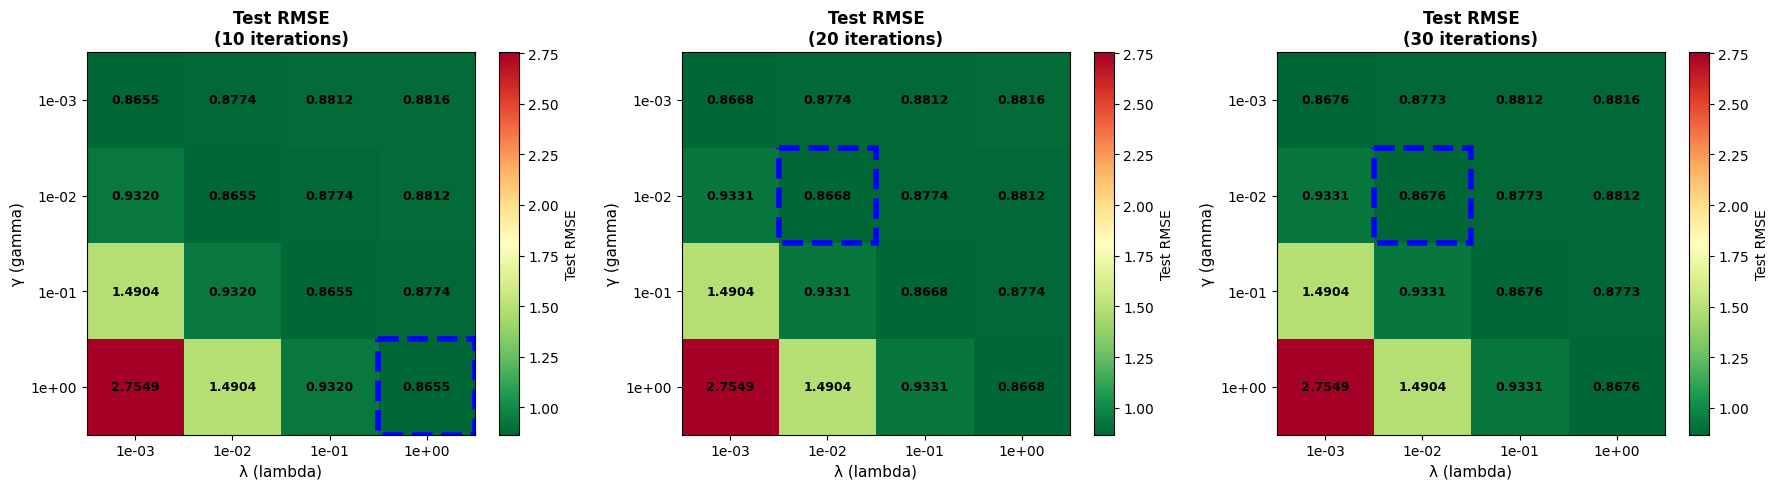

In [ ]:
# Create visualizations
plot_hyperparameter_heatmaps(results_df, save_path='hyperparameter_heatmaps.pdf')

/tmp/ipython-input-3088411185.py:66: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax4.scatter(overfit['final_train_rmse'], overfit['final_test_rmse'],


Comparison plots saved to: hyperparameter_comparison.pdf


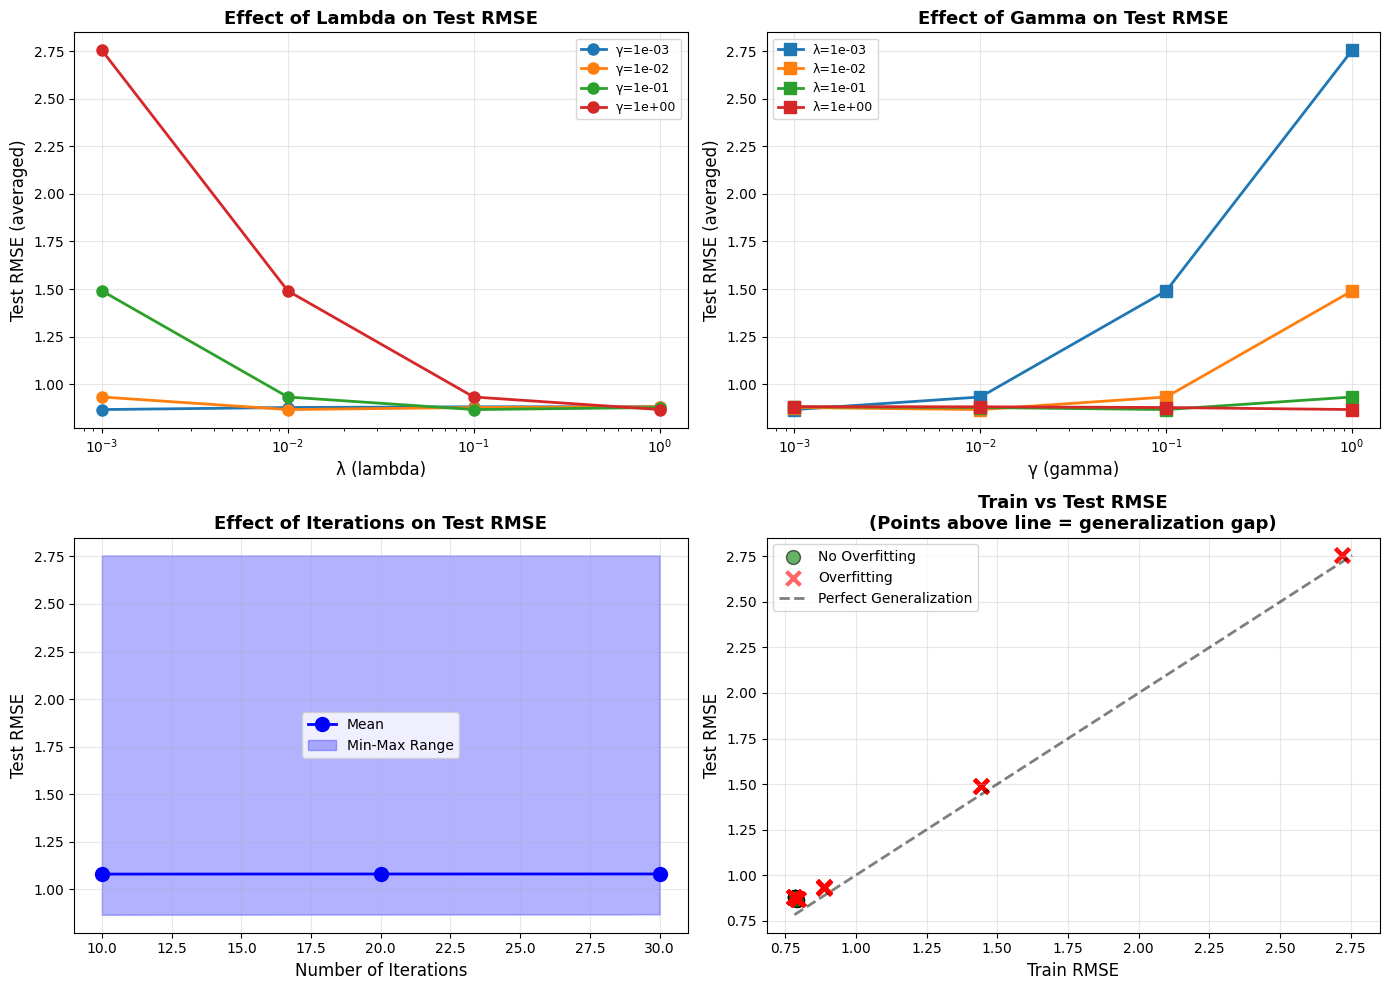

In [ ]:
plot_hyperparameter_comparison(results_df, save_path='hyperparameter_comparison.pdf')

✓ Best model training plot saved to: best_model_training.pdf


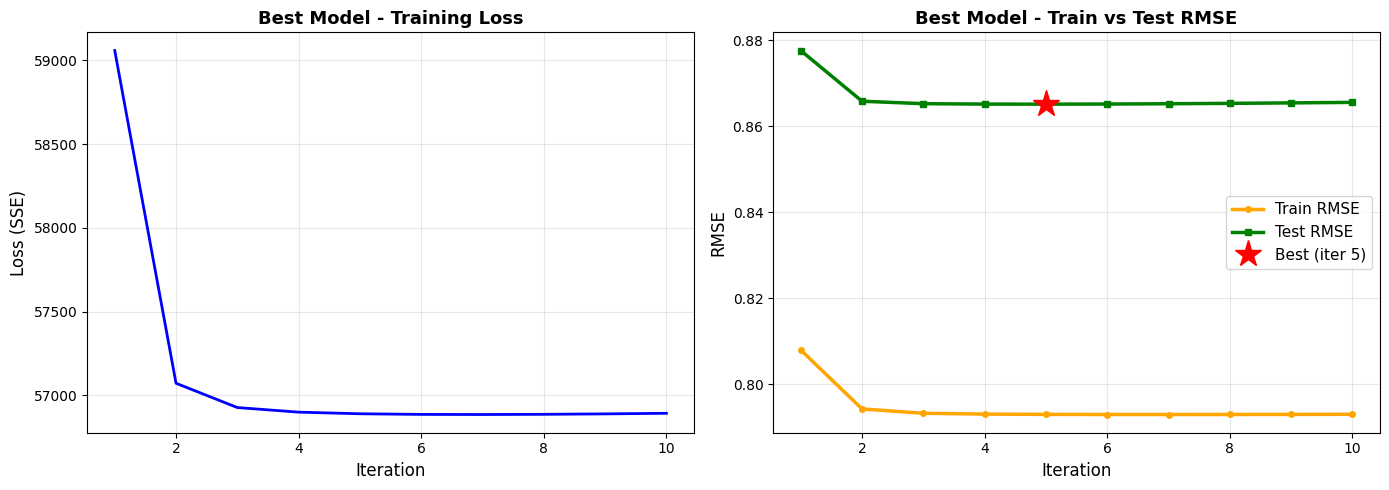

In [ ]:
plot_best_model_training(best_model, save_path='best_model_training.pdf')

The grid search successfully identified a high-performing configuration that stabilizes the model.

Best Configuration: λ=1.0, γ=1.0, with 10 iterations.

Performance: The test RMSE achieved is 0.8655.

While the grid search selected 10 iterations as the best final state, the training dynamics reveal that the true optimal point was actually at iteration 5 (RMSE 0.8651). The model begins to overfit slightly after this point.

There is a strong relationship between λ and γ. They do not function in isolation but must be balanced against each other, as according to the heatmaps, the best performance follows the diagonal trend.

The training curves indicate that the model learns very quickly but lacks the early stopping mechanism to stop at the perfect moment.

The top 5 models all show a good generalization gap of roughly +0.07 (Train ~0.79 vs Test ~0.86).

## **Practical 3: A model with embeddings**

Model initialization

Set up matrix factorization model with biases and embeddings.
#### Prediction Formula:
$$\hat{r}_{mn} = b_m^u + b_n^i + \mathbf{u}_m^\top \mathbf{v}_n$$

In [ ]:
M = number_of_users
N = number_of_movies
K = 10  # Embedding dimension

# Hyperparameters
lambd = 0.01
gamma = 0.01   # Bias regularization strength
tau = 0.5      # Embedding regularization strength
num_iters = 30

# Initialize biases to zero
user_biases = np.zeros(M)
item_biases = np.zeros(N)

# Initialize embeddings with small random values (break symmetry)
user_vectors = np.random.randn(M, K) * 0.01
item_vectors = np.random.randn(N, K) * 0.01

# Tracking metrics
loss_history = []
train_rmse_history = []
test_rmse_history = []

print("Matrix Factorization Model Configuration:")
print(f"  Users (M): {M:,}, Items (N): {N:,}")
print(f"  Embedding dimension (K): {K}")
print(f"  Learning rate (λ): {lambd}")
print(f"  Bias regularization (γ): {gamma}")
print(f"  Embedding regularization (τ): {tau}")
print(f"  Iterations: {num_iters}\n")

Matrix Factorization Model Configuration:
  Users (M): 610, Items (N): 9,724
  Embedding dimension (K): 10
  Learning rate (λ): 0.01
  Bias regularization (γ): 0.01
  Embedding regularization (τ): 0.5
  Iterations: 30



Alternative least square training

Finding the maximum likelihood estimate for biases and embeddings
#### Loss Function:

$$\mathcal{L} = \frac{λ}{2}\sum_{mn} \left(r_{mn} - b_m^u - b_n^i - \mathbf{u}_m^\top \mathbf{v}_n\right)^2 +\frac{\gamma}{2}\left(\sum_m b_m^u2 + \sum_n b_n^i2\right) + \frac{\tau}{2}\left(\sum_m \|\mathbf{u}_m\|^2 + \sum_i \|\mathbf{v}_n\|^2\right)$$

#### ALS Update Equations:

#### Phase 1: Fix Item Parameters $\{b_n^i, \mathbf{v}_n\}$, Optimize User Parameters $\{b_m^u, \mathbf{u}_m\}$

**User Bias Update:**

$$b_m^u = \frac{\lambda \sum_{n \in Ω(m)} (r_{mn} - b_n^i - \mathbf{u}_m^\top \mathbf{v}_n)}{\lambda|Ω(m)| + \gamma}$$

**User Embedding Update:**

$$\left(\lambda \sum_{n \in Ω(m)} \mathbf{v}_n \mathbf{v}_n^\top + \tau \mathbf{I}\right) \mathbf{u}_m = \lambda \sum_{n \in Ω(m)} (r_{mn} - b_m^u - b_n^i) \mathbf{v}_n$$

Which gives the linear system:

$$\mathbf{A} \mathbf{u}_m = \mathbf{b}$$
where

$$\mathbf{A} = \lambda \sum_{n \in Ω(m)} \mathbf{v}_n \mathbf{v}_n^\top + \tau \mathbf{I} \quad (k \times k \text{ matrix})$$

$$\mathbf{b} = \lambda \sum_{n \in Ω(m)} (r_{mn} - b_m^u - b_n^u) \mathbf{v}_n \quad (k \times 1 \text{ vector})$$

#### Phase 2: Fix User Parameters $\{b_m^u, \mathbf{u}_m\}$, Optimize Item Parameters $\{b_n^i, \mathbf{v}_n\}$

**Item Bias Update:**

$$b_n^i = \frac{\lambda \sum_{m \in Ω(n)} (r_{mn} - b_m^u - \mathbf{u}_m^\top \mathbf{v}_n)}{\lambda|Ω(n)| + \gamma}$$

**Item Embedding Update:**

$$\left(\lambda \sum_{u \in Ω(n)} \mathbf{u}_m \mathbf{u}_m^\top + \tau \mathbf{I}\right) \mathbf{v}_n = \lambda \sum_{u \in Ω(n)} (r_{mn} - b_m^u - b_n^i) \mathbf{u}_m$$

#### RMSE Formula:

$$\text{RMSE} = \sqrt{\frac{\sum_{mn} (r_{mn} - \hat{r}_{mn})^2}{n_{~of~ratings}}}$$

### Without Parallelization

In [ ]:
# def update_user_biases_m_e(data_by_user_train, M, user_biases, user_vectors, item_biases, item_vectors, lambd, gamma):
#     """
#     Updates user biases by iterating through users and optimizing for the residual.
#     """
#     for user_idx in range(M):
#         user_ratings = data_by_user_train[user_idx]

#         if len(user_ratings) == 0:
#             continue

#         # Keep embedding fixed, optimize bias
#         bias_numerator = 0

#         for movie_idx, rating in user_ratings:
#             # Prediction without user bias
#             prediction_no_bias = (item_biases[movie_idx] +
#                                  np.dot(user_vectors[user_idx], item_vectors[movie_idx]))
#             residual = rating - prediction_no_bias
#             bias_numerator += lambd * residual

#         user_biases[user_idx] = bias_numerator / (lambd * len(user_ratings) + gamma)

In [ ]:
# def update_user_vectors_m_e(data_by_user_train, M, user_biases, user_vectors, item_biases, item_vectors, lambd, tau):
#     """
#     Updates user embeddings by solving the linear system.
#     """
#     for user_idx in range(M):
#         user_ratings = data_by_user_train[user_idx]

#         if len(user_ratings) == 0:
#             continue

#         # Initialize linear system components
#         A_matrix = np.zeros((K, K))
#         b_vector = np.zeros(K)

#         for movie_idx, rating in user_ratings:
#             # Residual after removing both biases
#             residual = rating - user_biases[user_idx] - item_biases[movie_idx]

#             item_vec = item_vectors[movie_idx]

#             # Build linear system:
#             A_matrix += lambd * np.outer(item_vec, item_vec)
#             b_vector += lambd * residual * item_vec

#         # Add regularization:
#         A_matrix += tau * np.eye(K)

#         # Solve for user vector
#         user_vectors[user_idx] = np.linalg.solve(A_matrix, b_vector)


In [ ]:
# def update_item_biases_m_e(data_by_movie_train, N, user_biases, user_vectors, item_biases, item_vectors, lambd, gamma):
#     """
#     Updates item biases by iterating through movies and optimizing for the residual.
#     """
#     for movie_idx in range(N):
#         movie_ratings = data_by_movie_train[movie_idx]

#         if len(movie_ratings) == 0:
#             continue

#         # Keep embedding fixed, optimize bias
#         bias_numerator = 0

#         for user_idx, rating in movie_ratings:
#             # Prediction without item bias
#             prediction_no_bias = (user_biases[user_idx] +
#                                  np.dot(user_vectors[user_idx], item_vectors[movie_idx]))
#             residual = rating - prediction_no_bias
#             bias_numerator += lambd * residual

#         item_biases[movie_idx] = bias_numerator / (lambd * len(movie_ratings) + gamma)


In [ ]:
# def update_item_vectors_m_e(data_by_movie_train, N, user_biases, user_vectors, item_biases, item_vectors, lambd, tau):
#     """
#     Updates item embeddings by solving the linear system.
#     """
#     for movie_idx in range(N):
#         movie_ratings = data_by_movie_train[movie_idx]

#         if len(movie_ratings) == 0:
#             continue

#         # Initialize linear system
#         A_matrix = np.zeros((K, K))
#         b_vector = np.zeros(K)

#         for user_idx, rating in movie_ratings:
#             # Residual after removing both biases
#             residual = rating - user_biases[user_idx] - item_biases[movie_idx]

#             user_vec = user_vectors[user_idx]

#             # Build linear system:
#             A_matrix += lambd * np.outer(user_vec, user_vec)
#             b_vector += lambd * residual * user_vec

#         # Add regularization:
#         A_matrix += tau * np.eye(K)

#         # Solve for item vector
#         item_vectors[movie_idx] = np.linalg.solve(A_matrix, b_vector)

In [ ]:
# def evaluate_rmse_m_e(data_by_user_train, M, user_biases, user_vectors, item_biases, item_vectors):
#     """
#     Calculates RMSE for a given dataset (train or test).
#     """
#     sse = 0
#     count = 0

#     for user_idx in range(M):
#         for movie_idx, rating in data_by_user_train[user_idx]:
#             # Full prediction: bias + bias + embedding interaction
#             prediction = (user_biases[user_idx] +
#                           item_biases[movie_idx] +
#                           np.dot(user_vectors[user_idx], item_vectors[movie_idx]))

#             error = rating - prediction
#             sse += error ** 2
#             count += 1

#     return np.sqrt(sse / count) if count > 0 else 0.0

In [ ]:
# def train_model_m_e(data_by_user_train, data_by_movie_train, data_by_user_test, M, N, lambd, gamma, num_iters, verbose=True):
#     """
#     Orchestrates the ALS training loop.
#     Uses global variables for model parameters (user_biases, etc.) as they are not passed in arguments.
#     """
#     print("Starting Alternating Least Squares Training...")
#     print("=" * 60)

#     # Initialize history lists
#     loss_history = []
#     train_rmse_history = []
#     test_rmse_history = []

#     for iteration in range(num_iters):
#         # PHASE 1: UPDATE USER PARAMETERS (fix all item parameters)
#         update_user_biases_m_e(data_by_user_train, M, user_biases, user_vectors, item_biases, item_vectors, lambd, gamma)
#         update_user_vectors_m_e(data_by_user_train, M, user_biases, user_vectors, item_biases, item_vectors, lambd, tau)

#         # PHASE 2: UPDATE ITEM PARAMETERS (fix all user parameters)
#         # Note: We pass data_by_movie_train here to match the item update logic
#         update_item_biases_m_e(data_by_movie_train, N, user_biases, user_vectors, item_biases, item_vectors, lambd, gamma)
#         update_item_vectors_m_e(data_by_movie_train, N, user_biases, user_vectors, item_biases, item_vectors, lambd, tau)

#         # EVALUATION
#         train_rmse = evaluate_rmse_m_e(data_by_user_train, M, user_biases, user_vectors, item_biases, item_vectors)
#         test_rmse = evaluate_rmse_m_e(data_by_user_test, M, user_biases, user_vectors, item_biases, item_vectors)

#         train_rmse_history.append(train_rmse)
#         test_rmse_history.append(test_rmse)

#         # Calculate total loss for reporting
#         # Re-calculate train_sse derived from RMSE to match original logic's reporting
#         # (Since evaluate_rmse returns sqrt(MSE), we reverse it roughly for the loss sum)
#         train_count = sum(len(ratings) for ratings in data_by_user_train)
#         train_sse = (train_rmse ** 2) * train_count

#         bias_regularization = gamma * (np.sum(user_biases**2) + np.sum(item_biases**2))
#         embedding_regularization = tau * (np.sum(user_vectors**2) + np.sum(item_vectors**2))
#         total_loss = train_sse + bias_regularization + embedding_regularization
#         loss_history.append(total_loss)

#         if verbose:
#             print(f"Iter {iteration+1:2d}/{num_iters}: "
#                   f"Loss = {total_loss:,.0f}, "
#                   f"Train RMSE = {train_rmse:.4f}, "
#                   f"Test RMSE = {test_rmse:.4f}")

#     print("=" * 60)
#     print("Training Complete!\n")
#     print(f"Final Train RMSE: {train_rmse_history[-1]:.4f}")
#     print(f"Final Test RMSE:  {test_rmse_history[-1]:.4f}")
#     print(f"Generalization Gap: {test_rmse_history[-1] - train_rmse_history[-1]:.4f}\n")

#     # Returning the history and parameters is useful, though the original just printed.
#     return {
#         'user_biases': user_biases,
#         'user_embedding': user_vectors,
#         'item_biases': item_biases,
#         'item_embedding': item_vectors,
#         'loss_history': loss_history,
#         'train_rmse_history': train_rmse_history,
#         'test_rmse_history': test_rmse_history
#     }

In [ ]:
# # Train the model
# results = train_model_m_e(
#     data_by_user_train,
#     data_by_movie_train,
#     data_by_user_test,
#     M, N,
#     lambd, gamma,
#     num_iters,
#     verbose=True
# )

# # Extract results
# final_user_biases = results['user_biases']
# final_user_embeddings = results['user_embedding']
# final_item_biases = results['item_biases']
# final_item_embeddings = results['item_embedding']
# loss_history = results['loss_history']
# train_rmse = results['train_rmse_history']
# test_rmse = results['test_rmse_history']

### With Paralellization using Numba-JIT

In [ ]:
@njit(parallel=True)
def update_user_biases_m_e(user_vals, user_idx, user_map,
                                 user_biases, user_vectors,
                                 item_biases, item_vectors,
                                 lambd, gamma):
    """
    Update user biases in parallel.
    """
    M = user_map.shape[0]

    for user_id in prange(M):
        start_idx = user_map[user_id, 0]
        end_idx = user_map[user_id, 1]

        if start_idx == end_idx:
            continue

        bias_numerator = 0.0

        for ptr in range(start_idx, end_idx):
            movie_id = user_idx[ptr]
            rating = user_vals[ptr]

            # Prediction without user bias
            dot_product = 0.0
            for k in range(user_vectors.shape[1]):
                dot_product += user_vectors[user_id, k] * item_vectors[movie_id, k]

            prediction_no_bias = item_biases[movie_id] + dot_product
            residual = rating - prediction_no_bias
            bias_numerator += lambd * residual

        count = end_idx - start_idx
        user_biases[user_id] = bias_numerator / (lambd * count + gamma)

In [ ]:
@njit(parallel=True)
def update_user_vectors_m_e(user_vals, user_idx, user_map,
                                  user_biases, user_vectors,
                                  item_biases, item_vectors,
                                  lambd, tau):
    """
    Update user embedding vectors in parallel.
    """
    M = user_map.shape[0]
    K = user_vectors.shape[1]

    for user_id in prange(M):
        start_idx = user_map[user_id, 0]
        end_idx = user_map[user_id, 1]

        if start_idx == end_idx:
            continue

        # Initialize A matrix and b vector
        A_matrix = np.zeros((K, K), dtype=np.float64)
        b_vector = np.zeros(K, dtype=np.float64)

        for ptr in range(start_idx, end_idx):
            movie_id = user_idx[ptr]
            rating = user_vals[ptr]

            # Residual after removing biases
            residual = rating - user_biases[user_id] - item_biases[movie_id]

            # Build linear system: A = λ Σ vᵢvᵢᵀ, b = λ Σ residual·vᵢ
            for k1 in range(K):
                b_vector[k1] += lambd * residual * item_vectors[movie_id, k1]
                for k2 in range(K):
                    A_matrix[k1, k2] += lambd * item_vectors[movie_id, k1] * item_vectors[movie_id, k2]

        # Add regularization: A + τI
        for k in range(K):
            A_matrix[k, k] += tau

        # Solve linear system: A·uᵤ = b
        user_vectors[user_id] = np.linalg.solve(A_matrix, b_vector)

In [ ]:
@njit(parallel=True)
def update_item_biases_m_e(item_vals, item_idx, item_map,
                                 user_biases, user_vectors,
                                 item_biases, item_vectors,
                                 lambd, gamma):
    """
    Update item biases in parallel.
    """
    N = item_map.shape[0]

    for movie_id in prange(N):
        start_idx = item_map[movie_id, 0]
        end_idx = item_map[movie_id, 1]

        if start_idx == end_idx:
            continue

        bias_numerator = 0.0

        for ptr in range(start_idx, end_idx):
            user_id = item_idx[ptr]
            rating = item_vals[ptr]

            # Prediction without item bias
            dot_product = 0.0
            for k in range(user_vectors.shape[1]):
                dot_product += user_vectors[user_id, k] * item_vectors[movie_id, k]

            prediction_no_bias = user_biases[user_id] + dot_product
            residual = rating - prediction_no_bias
            bias_numerator += lambd * residual

        count = end_idx - start_idx
        item_biases[movie_id] = bias_numerator / (lambd * count + gamma)

In [ ]:
@njit(parallel=True)
def update_item_vectors_m_e(item_vals, item_idx, item_map,
                                  user_biases, user_vectors,
                                  item_biases, item_vectors,
                                  lambd, tau):
    """
    Update item embedding vectors in parallel.
    """
    N = item_map.shape[0]
    K = item_vectors.shape[1]

    for movie_id in prange(N):
        start_idx = item_map[movie_id, 0]
        end_idx = item_map[movie_id, 1]

        if start_idx == end_idx:
            continue

        # Initialize A matrix and b vector
        A_matrix = np.zeros((K, K), dtype=np.float64)
        b_vector = np.zeros(K, dtype=np.float64)

        for ptr in range(start_idx, end_idx):
            user_id = item_idx[ptr]
            rating = item_vals[ptr]

            # Residual after removing biases
            residual = rating - user_biases[user_id] - item_biases[movie_id]

            # Build linear system: A = λ Σ uᵤuᵤᵀ, b = λ Σ residual·uᵤ
            for k1 in range(K):
                b_vector[k1] += lambd * residual * user_vectors[user_id, k1]
                for k2 in range(K):
                    A_matrix[k1, k2] += lambd * user_vectors[user_id, k1] * user_vectors[user_id, k2]

        # Add regularization: A + τI
        for k in range(K):
            A_matrix[k, k] += tau

        # Solve linear system: A·vᵢ = b
        item_vectors[movie_id] = np.linalg.solve(A_matrix, b_vector)


In [ ]:
@njit
def evaluate_rmse_m_e(user_vals, user_idx, user_map,
                            user_biases, user_vectors,
                            item_biases, item_vectors):
    """
    Calculate RMSE for matrix factorization model.

    Prediction: r̂ᵤᵢ = bᵤ + bᵢ + uᵤᵀvᵢ
    """
    M = user_map.shape[0]
    K = user_vectors.shape[1]

    sse = 0.0
    count = 0

    for user_id in range(M):
        start_idx = user_map[user_id, 0]
        end_idx = user_map[user_id, 1]

        for ptr in range(start_idx, end_idx):
            movie_id = user_idx[ptr]
            rating = user_vals[ptr]

            # Full prediction with biases and embeddings
            dot_product = 0.0
            for k in range(K):
                dot_product += user_vectors[user_id, k] * item_vectors[movie_id, k]

            prediction = user_biases[user_id] + item_biases[movie_id] + dot_product
            error = rating - prediction
            sse += error * error
            count += 1

    rmse = np.sqrt(sse / count) if count > 0 else np.inf
    return rmse, sse, count

In [ ]:
def train_model_m_e(data_by_user_train, data_by_movie_train,
                                        data_by_user_test, M, N, K,
                                        lambd, gamma, tau,
                                        num_iters, verbose=True):
    """
    Train matrix factorization model with parallel Numba optimization.
    Returns
    dict with trained model and history
    """

    if verbose:
        print("Preparing flat data structures for parallel Numba execution...")

    # Flatten training data
    train_user_vals, train_user_idx, train_user_map, \
    train_item_vals, train_item_idx, train_item_map = \
        prepare_flat_data(data_by_user_train, data_by_movie_train, M, N)

    # Flatten test data
    test_user_vals, test_user_idx, test_user_map, _, _, _ = \
        prepare_flat_data(data_by_user_test, [[] for _ in range(N)], M, N)

    # Initialize parameters
    user_biases = np.zeros(M, dtype=np.float64)
    item_biases = np.zeros(N, dtype=np.float64)
    user_vectors = np.random.randn(M, K).astype(np.float64) * 0.01
    item_vectors = np.random.randn(N, K).astype(np.float64) * 0.01

    # Track metrics
    loss_history = []
    train_rmse_history = []
    test_rmse_history = []

    if verbose:
        print("Starting Parallel Matrix Factorization Training...")
        print("=" * 70)
        print(f"Parameters: M={M:,}, N={N:,}, K={K}")
        print(f"Hyperparameters: λ={lambd}, γ={gamma}, τ={tau}")
        print(f"Iterations: {num_iters}")
        print()

    # Training loop
    for iteration in range(num_iters):

        # PHASE 1: Update user parameters (parallel)
        update_user_biases_m_e(train_user_vals, train_user_idx, train_user_map,
                                     user_biases, user_vectors,
                                     item_biases, item_vectors,
                                     lambd, gamma)

        update_user_vectors_m_e(train_user_vals, train_user_idx, train_user_map,
                                      user_biases, user_vectors,
                                      item_biases, item_vectors,
                                      lambd, tau)

        # PHASE 2: Update item parameters (parallel)
        update_item_biases_m_e(train_item_vals, train_item_idx, train_item_map,
                                     user_biases, user_vectors,
                                     item_biases, item_vectors,
                                     lambd, gamma)

        update_item_vectors_m_e(train_item_vals, train_item_idx, train_item_map,
                                      user_biases, user_vectors,
                                      item_biases, item_vectors,
                                      lambd, tau)

        # Evaluate on training set
        train_rmse, train_sse, train_count = evaluate_rmse_m_e(
            train_user_vals, train_user_idx, train_user_map,
            user_biases, user_vectors, item_biases, item_vectors
        )
        train_rmse_history.append(train_rmse)

        # Calculate total loss with regularization
        bias_reg = gamma * (np.sum(user_biases**2) + np.sum(item_biases**2))
        embed_reg = tau * (np.sum(user_vectors**2) + np.sum(item_vectors**2))
        total_loss = train_sse + bias_reg + embed_reg
        loss_history.append(total_loss)

        # Evaluate on test set
        test_rmse, test_sse, test_count = evaluate_rmse_m_e(
            test_user_vals, test_user_idx, test_user_map,
            user_biases, user_vectors, item_biases, item_vectors
        )
        test_rmse_history.append(test_rmse)

        if verbose:
            print(f"Iter {iteration+1:2d}/{num_iters}: "
                  f"Loss = {total_loss:,.0f}, "
                  f"Train RMSE = {train_rmse:.4f}, "
                  f"Test RMSE = {test_rmse:.4f}")

    if verbose:
        print("=" * 70)
        print("Training Complete!\n")
        print(f"Final Train RMSE: {train_rmse_history[-1]:.4f}")
        print(f"Final Test RMSE:  {test_rmse_history[-1]:.4f}")
        print(f"Generalization Gap: "
              f"{test_rmse_history[-1] - train_rmse_history[-1]:.4f}\n")

    return {
        'user_biases': user_biases,
        'user_vectors': user_vectors,
        'item_biases': item_biases,
        'item_vectors': item_vectors,
        'loss_history': loss_history,
        'train_rmse_history': train_rmse_history,
        'test_rmse_history': test_rmse_history
    }

In [ ]:
# Train the model
results = train_model_m_e(
    data_by_user_train=data_by_user_train,
    data_by_movie_train=data_by_movie_train,
    data_by_user_test=data_by_user_test,
    M=M, N=N, K=K,
    lambd=lambd,
    gamma=gamma,
    tau=tau,
    num_iters=num_iters,
    verbose=True
)

# Extract results
user_biases = results['user_biases']
user_vectors = results['user_vectors']
item_biases = results['item_biases']
item_vectors = results['item_vectors']
loss_history = results['loss_history']
train_rmse_history = results['train_rmse_history']
test_rmse_history = results['test_rmse_history']

Preparing flat data structures for parallel Numba execution...
Starting Parallel Matrix Factorization Training...
Parameters: M=610, N=9,724, K=10
Hyperparameters: λ=0.01, γ=0.01, τ=0.5
Iterations: 30

Iter  1/30: Loss = 59,160, Train RMSE = 0.8079, Test RMSE = 0.8776
Iter  2/30: Loss = 57,172, Train RMSE = 0.7942, Test RMSE = 0.8658
Iter  3/30: Loss = 57,026, Train RMSE = 0.7932, Test RMSE = 0.8652
Iter  4/30: Loss = 56,997, Train RMSE = 0.7930, Test RMSE = 0.8651
Iter  5/30: Loss = 56,986, Train RMSE = 0.7929, Test RMSE = 0.8651
Iter  6/30: Loss = 56,981, Train RMSE = 0.7929, Test RMSE = 0.8651
Iter  7/30: Loss = 56,979, Train RMSE = 0.7929, Test RMSE = 0.8652
Iter  8/30: Loss = 56,980, Train RMSE = 0.7929, Test RMSE = 0.8653
Iter  9/30: Loss = 56,982, Train RMSE = 0.7929, Test RMSE = 0.8654
Iter 10/30: Loss = 56,985, Train RMSE = 0.7930, Test RMSE = 0.8655
Iter 11/30: Loss = 56,988, Train RMSE = 0.7930, Test RMSE = 0.8657
Iter 12/30: Loss = 56,993, Train RMSE = 0.7930, Test RMSE = 0

Visualization

Visualizing training dynamics

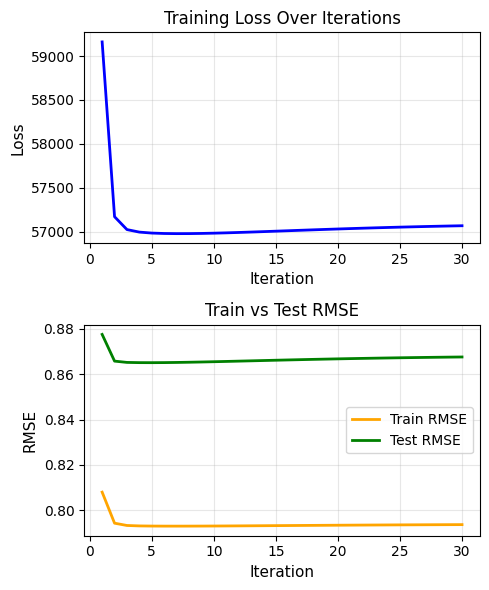


Model Summary:
  User embeddings shape: (610, 10)
  Item embeddings shape: (9724, 10)
  Total parameters: 113,674
  Each user/item represented by 10-dimensional latent vector


In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(5, 6))

# Plot 1: Total Loss (with regularization)
ax1.plot(range(1, num_iters + 1), loss_history, 'b-', linewidth=2)
ax1.set_xlabel('Iteration', fontsize=11)
ax1.set_ylabel('Loss', fontsize=11)
ax1.set_title('Training Loss Over Iterations',
              fontsize=12)
ax1.grid(True, alpha=0.3)

# Plot 2: Train vs Test RMSE
ax2.plot(range(1, num_iters + 1), train_rmse_history,
         'orange', linewidth=2, label='Train RMSE')
ax2.plot(range(1, num_iters + 1), test_rmse_history,
         'green', linewidth=2, label='Test RMSE')
ax2.set_xlabel('Iteration', fontsize=11)
ax2.set_ylabel('RMSE', fontsize=11)
ax2.set_title('Train vs Test RMSE', fontsize=12)
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('matrix_factorization_training.pdf', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nModel Summary:")
print(f"  User embeddings shape: {user_vectors.shape}")
print(f"  Item embeddings shape: {item_vectors.shape}")
print(f"  Total parameters: {M + N + M*K + N*K:,}")
print(f"  Each user/item represented by {K}-dimensional latent vector")

### Hyper-parameter tuning

In [ ]:
def staged_grid_search(data_by_user_train, data_by_movie_train,
                       data_by_user_test, M, N,
                       train_function, verbose=True):
    """
    Perform staged hyperparameter search for matrix factorization.

    Stage 1: Coarse search on K and τ (most important)
    Stage 2: Fine-tune best K and τ
    Stage 3: Tune λ and γ with best K and τ

    Returns
    dict with all stage results and best configuration
    """

    all_results = []

    # STAGE 1: Coarse Search on K and τ

    if verbose:
        print("=" * 70)
        print("STAGE 1: Coarse Search on K (embedding dim) and τ (embed reg)")
        print("=" * 70)
        print("Strategy: These parameters have the largest impact on performance")
        print("Fixed: λ=0.01, γ=0.01, iters=30\n")

    stage1_K = [10, 20, 30]
    stage1_tau = [0.01, 0.1, 1.0]
    stage1_lambda = 0.01
    stage1_gamma = 0.01
    stage1_iters = 15

    stage1_results = []

    for K, tau in product(stage1_K, stage1_tau):
        if verbose:
            print(f"Testing: K={K}, τ={tau}")

        results = train_function(
            data_by_user_train, data_by_movie_train, data_by_user_test,
            M, N, K, lambd=stage1_lambda, gamma=stage1_gamma,
            tau=tau, num_iters=stage1_iters, verbose=False
        )

        config = {
            'stage': 1,
            'K': K,
            'lambda': stage1_lambda,
            'gamma': stage1_gamma,
            'tau': tau,
            'num_iters': stage1_iters,
            'train_rmse': results['train_rmse_history'][-1],
            'test_rmse': results['test_rmse_history'][-1],
            'best_test_rmse': min(results['test_rmse_history']),
            'results': results
        }

        stage1_results.append(config)
        all_results.append(config)

        if verbose:
            print(f"Test RMSE: {config['test_rmse']:.4f}\n")

    # Find best from Stage 1
    best_stage1 = min(stage1_results, key=lambda x: x['test_rmse'])
    best_K = best_stage1['K']
    best_tau = best_stage1['tau']

    if verbose:
        print(f"Stage 1 Best: K={best_K}, τ={best_tau}, "
              f"Test RMSE={best_stage1['test_rmse']:.4f}\n")


    # STAGE 2: Fine-tune K and τ around best values

    if verbose:
        print("=" * 70)
        print("STAGE 2: Fine-tune K and τ")
        print("=" * 70)
        print(f"Strategy: Search around best values from Stage 1\n")

    # Define fine-tuning ranges based on best values
    if best_K == 10:
        stage2_K = [5, 10, 15]
    elif best_K == 20:
        stage2_K = [15, 20, 25]
    else:
        stage2_K = [25, 30, 35]

    if best_tau <= 0.01:
        stage2_tau = [0.005, 0.01, 0.05]
    elif best_tau <= 0.1:
        stage2_tau = [0.05, 0.1, 0.5]
    else:
        stage2_tau = [0.5, 1.0, 2.0]

    stage2_results = []

    for K, tau in product(stage2_K, stage2_tau):
        # Skip if already tested in Stage 1
        if any(r['K'] == K and r['tau'] == tau for r in stage1_results):
            continue

        if verbose:
            print(f"Testing: K={K}, τ={tau}")

        results = train_function(
            data_by_user_train, data_by_movie_train, data_by_user_test,
            M, N, K, lambd=stage1_lambda, gamma=stage1_gamma,
            tau=tau, num_iters=stage1_iters, verbose=False
        )

        config = {
            'stage': 2,
            'K': K,
            'lambda': stage1_lambda,
            'gamma': stage1_gamma,
            'tau': tau,
            'num_iters': stage1_iters,
            'train_rmse': results['train_rmse_history'][-1],
            'test_rmse': results['test_rmse_history'][-1],
            'best_test_rmse': min(results['test_rmse_history']),
            'results': results
        }

        stage2_results.append(config)
        all_results.append(config)

        if verbose:
            print(f"Test RMSE: {config['test_rmse']:.4f}\n")

    # Find best from Stage 2
    best_stage2 = min(stage1_results + stage2_results, key=lambda x: x['test_rmse'])
    best_K = best_stage2['K']
    best_tau = best_stage2['tau']

    if verbose:
        print(f"Stage 2 Best: K={best_K}, τ={best_tau}, "
              f"Test RMSE={best_stage2['test_rmse']:.4f}\n")


    # STAGE 3: Tune λ and γ with best K and τ

    if verbose:
        print("=" * 70)
        print("STAGE 3: Tune λ (learning rate) and γ (bias reg)")
        print("=" * 70)
        print(f"Strategy: Fix best K={best_K}, τ={best_tau}, vary λ and γ\n")

    stage3_lambda = [0.001, 0.01, 0.1]
    stage3_gamma = [0.001, 0.01, 0.1]
    stage3_results = []

    for lambd, gamma in product(stage3_lambda, stage3_gamma):
        if verbose:
            print(f"Testing: λ={lambd}, γ={gamma}")

        results = train_function(
            data_by_user_train, data_by_movie_train, data_by_user_test,
            M, N, best_K, lambd=lambd, gamma=gamma,
            tau=best_tau, num_iters=stage1_iters, verbose=False
        )

        config = {
            'stage': 3,
            'K': best_K,
            'lambda': lambd,
            'gamma': gamma,
            'tau': best_tau,
            'num_iters': stage1_iters,
            'train_rmse': results['train_rmse_history'][-1],
            'test_rmse': results['test_rmse_history'][-1],
            'best_test_rmse': min(results['test_rmse_history']),
            'results': results
        }

        stage3_results.append(config)
        all_results.append(config)

        if verbose:
            print(f"Test RMSE: {config['test_rmse']:.4f}\n")

    # Find overall best
    best_overall = min(all_results, key=lambda x: x['test_rmse'])

    if verbose:
        print("=" * 70)
        print("HYPERPARAMETER SEARCH COMPLETE!")
        print("=" * 70)
        print(f"\nBEST CONFIGURATION:")
        print(f"   K (embedding dim):     {best_overall['K']}")
        print(f"   λ (learning rate):     {best_overall['lambda']}")
        print(f"   γ (bias reg):          {best_overall['gamma']}")
        print(f"   τ (embedding reg):     {best_overall['tau']}")
        print(f"   Iterations:            {best_overall['num_iters']}")
        print(f"\nBEST PERFORMANCE:")
        print(f"   Test RMSE:             {best_overall['test_rmse']:.4f}")
        print(f"   Train RMSE:            {best_overall['train_rmse']:.4f}")
        print(f"   Gap:                   {best_overall['test_rmse'] - best_overall['train_rmse']:+.4f}")
        print(f"\n   Total configurations tested: {len(all_results)}")
        print("=" * 70)

    return {
        'all_results': all_results,
        'stage1_results': stage1_results,
        'stage2_results': stage2_results,
        'stage3_results': stage3_results,
        'best_config': best_overall
    }

In [ ]:
def plot_staged_search_results(search_results, save_path='staged_search.pdf'):
    """Visualize results from staged grid search."""

    all_results = search_results['all_results']
    best_config = search_results['best_config']

    # Convert to DataFrame
    df = pd.DataFrame([{k: v for k, v in r.items() if k != 'results'}
                       for r in all_results])

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Plot 1: K vs Test RMSE (grouped by tau)
    ax1 = axes[0, 0]
    for tau in sorted(df['tau'].unique()):
        subset = df[df['tau'] == tau]
        grouped = subset.groupby('K')['test_rmse'].mean()
        ax1.plot(grouped.index, grouped.values, marker='o', linewidth=2,
                label=f'τ={tau}', markersize=8)

    ax1.set_xlabel('K (Embedding Dimension)', fontsize=12)
    ax1.set_ylabel('Test RMSE (averaged)', fontsize=12)
    ax1.set_title('Effect of K on Test RMSE', fontsize=13, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3)

    # Plot 2: Tau vs Test RMSE (grouped by K)
    ax2 = axes[0, 1]
    for K in sorted(df['K'].unique()):
        subset = df[df['K'] == K]
        grouped = subset.groupby('tau')['test_rmse'].mean()
        ax2.plot(grouped.index, grouped.values, marker='s', linewidth=2,
                label=f'K={K}', markersize=8)

    ax2.set_xscale('log')
    ax2.set_xlabel('τ (Embedding Regularization)', fontsize=12)
    ax2.set_ylabel('Test RMSE (averaged)', fontsize=12)
    ax2.set_title('Effect of τ on Test RMSE', fontsize=13, fontweight='bold')
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)

    # Plot 3: Lambda vs Test RMSE
    ax3 = axes[1, 0]
    stage3_df = df[df['stage'] == 3]
    if len(stage3_df) > 0:
        grouped = stage3_df.groupby('lambda').agg({'test_rmse': ['mean', 'min', 'max']})
        lambdas = grouped.index
        means = grouped[('test_rmse', 'mean')].values
        mins = grouped[('test_rmse', 'min')].values
        maxs = grouped[('test_rmse', 'max')].values

        ax3.plot(lambdas, means, 'b-o', linewidth=2, markersize=10)
        ax3.fill_between(lambdas, mins, maxs, alpha=0.3, color='blue')
        ax3.set_xscale('log')
        ax3.set_xlabel('λ (Learning Rate)', fontsize=12)
        ax3.set_ylabel('Test RMSE', fontsize=12)
        ax3.set_title('Effect of λ on Test RMSE (Stage 3)', fontsize=13, fontweight='bold')
        ax3.grid(True, alpha=0.3)

    # Plot 4: All configurations performance
    ax4 = axes[1, 1]
    colors = {1: 'blue', 2: 'orange', 3: 'green'}
    for stage in [1, 2, 3]:
        stage_df = df[df['stage'] == stage]
        ax4.scatter(stage_df['train_rmse'], stage_df['test_rmse'],
                   c=colors[stage], s=100, alpha=0.6,
                   label=f'Stage {stage}', edgecolors='black')

    # Mark best configuration
    ax4.scatter(best_config['train_rmse'], best_config['test_rmse'],
               c='red', s=300, marker='*', edgecolors='black',
               linewidths=2, label='Best Config', zorder=10)

    # Diagonal line
    min_val = min(df['train_rmse'].min(), df['test_rmse'].min())
    max_val = max(df['train_rmse'].max(), df['test_rmse'].max())
    ax4.plot([min_val, max_val], [min_val, max_val], 'k--',
            linewidth=2, alpha=0.5)

    ax4.set_xlabel('Train RMSE', fontsize=12)
    ax4.set_ylabel('Test RMSE', fontsize=12)
    ax4.set_title('All Configurations: Train vs Test', fontsize=13, fontweight='bold')
    ax4.legend(fontsize=10)
    ax4.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"\nStaged search visualization saved to: {save_path}")
    plt.show()

Running STAGED grid search (efficient)...

STAGE 1: Coarse Search on K (embedding dim) and τ (embed reg)
Strategy: These parameters have the largest impact on performance
Fixed: λ=0.01, γ=0.01, iters=30

Testing: K=10, τ=0.01
Test RMSE: 1.0049

Testing: K=10, τ=0.1
Test RMSE: 0.8599

Testing: K=10, τ=1.0
Test RMSE: 0.8676

Testing: K=20, τ=0.01
Test RMSE: 1.0835

Testing: K=20, τ=0.1
Test RMSE: 0.8633

Testing: K=20, τ=1.0
Test RMSE: 0.8676

Testing: K=50, τ=0.01
Test RMSE: 1.0845

Testing: K=50, τ=0.1
Test RMSE: 0.8505

Testing: K=50, τ=1.0
Test RMSE: 0.8676

Stage 1 Best: K=50, τ=0.1, Test RMSE=0.8505

STAGE 2: Fine-tune K and τ
Strategy: Search around best values from Stage 1

Testing: K=30, τ=0.05
Test RMSE: 0.9248

Testing: K=30, τ=0.1
Test RMSE: 0.8583

Testing: K=30, τ=0.2
Test RMSE: 0.8549

Testing: K=30, τ=0.5
Test RMSE: 0.8676

Testing: K=40, τ=0.05
Test RMSE: 0.9152

Testing: K=40, τ=0.1
Test RMSE: 0.8535

Testing: K=40, τ=0.2
Test RMSE: 0.8549

Testing: K=40, τ=0.5
Test RMS

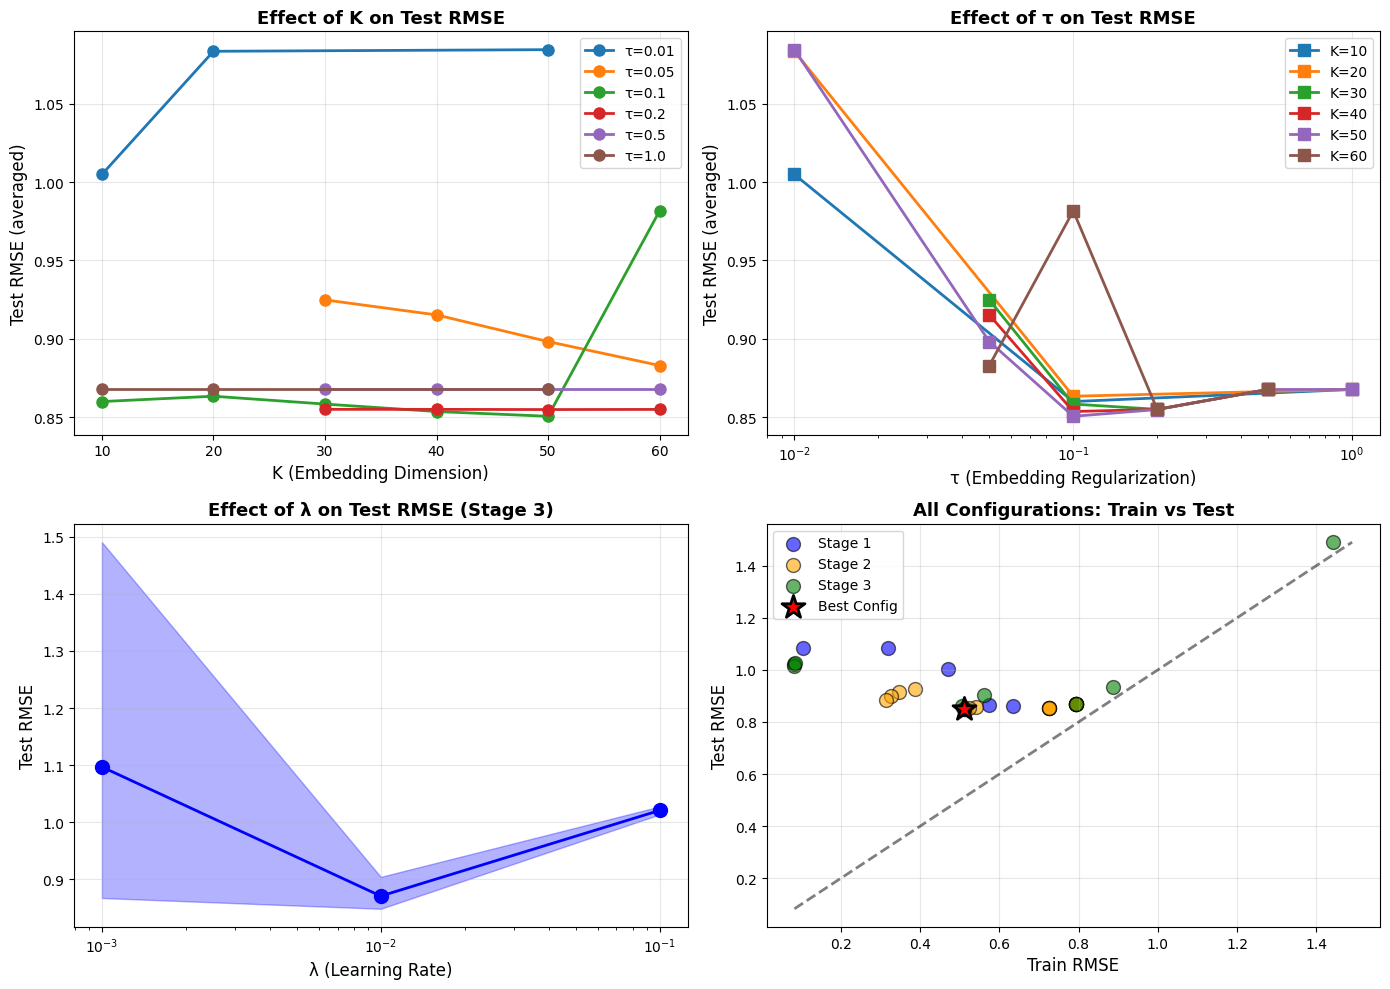

In [ ]:
print("Running STAGED grid search (efficient)...\n")

search_results = staged_grid_search(
    data_by_user_train=data_by_user_train,
    data_by_movie_train=data_by_movie_train,
    data_by_user_test=data_by_user_test,
    M=number_of_users,
    N=number_of_movies,
    train_function=train_model_m_e,
    verbose=True
)

# Visualize results
plot_staged_search_results(search_results, save_path='staged_search_results.pdf')

# Get best configuration
best_config = search_results['best_config']

## **Practical 4: Going big, training and testing**

### **1. Spliting the MovieLens 32M dataset**

To ensure every user has sufficient training data, I implement a per-user split strategy that prevents cold-start problems. For each user individually, I randomly shuffle their ratings and allocate 90% to the training set while reserving 10% for testing. This approach guarantees that all users contribute to model training while maintaining a consistent evaluation framework across the entire user base.


In [ ]:
# Load data
print("Loading ratings...")
ratings = np.loadtxt(
    "ml-32m/ml-32m/ratings.csv",
    delimiter=",",
    skiprows=1,
    usecols=(0, 1, 2)
)

users = ratings[:, 0].astype(int)
movies = ratings[:, 1].astype(int)
rating = ratings[:, 2].astype(float)

print(f"Loaded {len(ratings):,} ratings")

Loading ratings...
Loaded 32,000,204 ratings


In [ ]:
user_data, movie_data = build_indices(ratings)

userid_to_idx, idx_to_userid, data_by_user = user_data
movieid_to_idx, idx_to_movieid, data_by_movie = movie_data

Building index structures...
Indexed 200,948 users and 84,432 movies



### Spliting the ratings data into training (90%) and test (10%) sets

In [ ]:
# Split the 32M dataset into train and test

number_of_users = len(data_by_user)
number_of_movies = len(data_by_movie)
train_ratio = 0.9
random_seed =  42

data_by_user_train, data_by_user_test, data_by_movie_train, data_by_movie_test = \
    split_train_test(data_by_user, number_of_users, number_of_movies, train_ratio, random_seed, verbose=True)

Splitting data into train and test sets...
(90% train, 10% test)
Total ratings: 32,000,204
Train: 28,709,236 (89.7%)
Test: 3,290,968 (10.3%)



### Parallelization

In [ ]:
@njit(parallel=True)
def update_user_biases_m_e(user_vals, user_items, user_map, M, user_biases, user_vectors, item_biases, item_vectors, lambd, gamma):
    """
    Updates user biases in parallel.
    """
    # prange enables parallel execution of the loop
    for user_idx in prange(M):
        start = user_map[user_idx, 0]
        end = user_map[user_idx, 1]

        if start == end:
            continue

        bias_numerator = 0.0

        # Iterate over the slice of the flattened arrays
        for i in range(start, end):
            movie_idx = user_items[i]
            rating = user_vals[i]

            prediction_no_bias = (item_biases[movie_idx] +
                                 np.dot(user_vectors[user_idx], item_vectors[movie_idx]))
            residual = rating - prediction_no_bias
            bias_numerator += lambd * residual

        user_biases[user_idx] = bias_numerator / (lambd * (end - start) + gamma)

In [ ]:
@njit(parallel=True)
def update_user_vectors_m_e(user_vals, user_items, user_map, M, user_biases, user_vectors, item_biases, item_vectors, lambd, tau):
    """
    Updates user embeddings in parallel solving linear systems.
    """
    for user_idx in prange(M):
        start = user_map[user_idx, 0]
        end = user_map[user_idx, 1]

        if start == end:
            continue

        # Thread-local allocation for linear system
        # K is captured from global scope (must be constant or passed in)
        A_matrix = np.zeros((K, K), dtype=np.float64)
        b_vector = np.zeros(K, dtype=np.float64)

        for i in range(start, end):
            movie_idx = user_items[i]
            rating = user_vals[i]

            residual = rating - user_biases[user_idx] - item_biases[movie_idx]
            item_vec = item_vectors[movie_idx]

            # Manual outer product and addition is often faster in Numba than np.outer
            # But np.outer is supported.
            for k1 in range(K):
                for k2 in range(K):
                    A_matrix[k1, k2] += lambd * item_vec[k1] * item_vec[k2]
                b_vector[k1] += lambd * residual * item_vec[k1]

        # Add regularization
        for k in range(K):
            A_matrix[k, k] += tau

        # Solve
        user_vectors[user_idx] = np.linalg.solve(A_matrix, b_vector)

In [ ]:
@njit(parallel=True)
def update_item_biases_m_e(item_vals, item_users, item_map, N, user_biases, user_vectors, item_biases, item_vectors, lambd, gamma):
    """
    Updates item biases in parallel.
    """
    for movie_idx in prange(N):
        start = item_map[movie_idx, 0]
        end = item_map[movie_idx, 1]

        if start == end:
            continue

        bias_numerator = 0.0

        for i in range(start, end):
            user_idx = item_users[i]
            rating = item_vals[i]

            prediction_no_bias = (user_biases[user_idx] +
                                 np.dot(user_vectors[user_idx], item_vectors[movie_idx]))
            residual = rating - prediction_no_bias
            bias_numerator += lambd * residual

        item_biases[movie_idx] = bias_numerator / (lambd * (end - start) + gamma)

In [ ]:
@njit(parallel=True)
def update_item_vectors_m_e(item_vals, item_users, item_map, N, user_biases, user_vectors, item_biases, item_vectors, lambd, tau):
    """
    Updates item embeddings in parallel.
    """
    for movie_idx in prange(N):
        start = item_map[movie_idx, 0]
        end = item_map[movie_idx, 1]

        if start == end:
            continue

        A_matrix = np.zeros((K, K), dtype=np.float64)
        b_vector = np.zeros(K, dtype=np.float64)

        for i in range(start, end):
            user_idx = item_users[i]
            rating = item_vals[i]

            residual = rating - user_biases[user_idx] - item_biases[movie_idx]
            user_vec = user_vectors[user_idx]

            for k1 in range(K):
                for k2 in range(K):
                    A_matrix[k1, k2] += lambd * user_vec[k1] * user_vec[k2]
                b_vector[k1] += lambd * residual * user_vec[k1]

        for k in range(K):
            A_matrix[k, k] += tau

        item_vectors[movie_idx] = np.linalg.solve(A_matrix, b_vector)

In [ ]:
@njit(parallel=True)
def evaluate_rmse_m_e(vals, items, idx_map, M, user_biases, user_vectors, item_biases, item_vectors):
    """
    Calculates RMSE using Numba.
    Note: Can use either User or Item structures, usually User is used for evaluation.
    """
    sse = 0.0
    count = 0

    # Numba handles the reduction of scalar variables (sse, count) in prange automatically
    for user_idx in prange(M):
        start = idx_map[user_idx, 0]
        end = idx_map[user_idx, 1]

        if start == end:
            continue

        for i in range(start, end):
            movie_idx = items[i]
            rating = vals[i]

            prediction = (user_biases[user_idx] +
                          item_biases[movie_idx] +
                          np.dot(user_vectors[user_idx], item_vectors[movie_idx]))

            error = rating - prediction
            sse += error ** 2
            count += 1

    return np.sqrt(sse / count) if count > 0 else 0.0

In [ ]:
def train_model_m_e(data_by_user_train, data_by_movie_train, data_by_user_test, M, N, K, lambd, gamma, tau, num_iters, verbose=True):

    # 1. PREPARE FLAT DATA (One-time cost)
    print("Flattening data structures for Numba...")
    u_vals_tr, u_items_tr, u_map_tr, i_vals_tr, i_users_tr, i_map_tr = \
        prepare_flat_data(data_by_user_train, data_by_movie_train, M, N)

    # We also flatten test data for fast evaluation
    # Note: we pass data_by_user_test twice because we don't need the item-centric view for simple RMSE eval
    u_vals_te, u_items_te, u_map_te, _, _, _ = \
        prepare_flat_data(data_by_user_test, [], M, 0)

    print("Starting Numba Parallel ALS Training...")
    print("=" * 60)

    loss_history = []
    train_rmse_history = []
    test_rmse_history = []

    for iteration in range(num_iters):
        # PHASE 1: UPDATE USER PARAMETERS
        update_user_biases_m_e(u_vals_tr, u_items_tr, u_map_tr, M,
                               user_biases, user_vectors, item_biases, item_vectors, lambd, gamma)
        update_user_vectors_m_e(u_vals_tr, u_items_tr, u_map_tr, M,
                                user_biases, user_vectors, item_biases, item_vectors, lambd, tau)

        # PHASE 2: UPDATE ITEM PARAMETERS
        update_item_biases_m_e(i_vals_tr, i_users_tr, i_map_tr, N,
                               user_biases, user_vectors, item_biases, item_vectors, lambd, gamma)
        update_item_vectors_m_e(i_vals_tr, i_users_tr, i_map_tr, N,
                                user_biases, user_vectors, item_biases, item_vectors, lambd, tau)

        # EVALUATION
        train_rmse = evaluate_rmse_m_e(u_vals_tr, u_items_tr, u_map_tr, M,
                                       user_biases, user_vectors, item_biases, item_vectors)
        test_rmse = evaluate_rmse_m_e(u_vals_te, u_items_te, u_map_te, M,
                                      user_biases, user_vectors, item_biases, item_vectors)

        train_rmse_history.append(train_rmse)
        test_rmse_history.append(test_rmse)

        # Calculate total loss (approximate calculation for reporting)
        train_count = len(u_vals_tr)
        train_sse = (train_rmse ** 2) * train_count
        bias_reg = gamma * (np.sum(user_biases**2) + np.sum(item_biases**2))
        emb_reg = tau * (np.sum(user_vectors**2) + np.sum(item_vectors**2))
        total_loss = train_sse + bias_reg + emb_reg
        loss_history.append(total_loss)

        if verbose:
            print(f"Iter {iteration+1:2d}/{num_iters}: "
                  f"Loss = {total_loss:,.0f}, "
                  f"Train RMSE = {train_rmse:.4f}, "
                  f"Test RMSE = {test_rmse:.4f}")

    print("=" * 60)
    return {
        'user_biases': user_biases,
        'user_embedding': user_vectors,
        'item_biases': item_biases,
        'item_embedding': item_vectors,
        'loss_history': loss_history,
        'train_rmse_history': train_rmse_history,
        'test_rmse_history': test_rmse_history
    }

### Model initialization

In [ ]:
M = number_of_users
N = number_of_movies
K = 10  # Embedding dimension

# Hyperparameters
lambd = 0.01   # Learning rate
gamma = 0.01   # Bias regularization
tau = 0.1      # Embedding regularization
num_iters = 50

# Initialize parameters
user_biases = np.zeros(M)
item_biases = np.zeros(N)
user_vectors = np.random.randn(M, K) * 0.01
item_vectors = np.random.randn(N, K) * 0.01

# Tracking metrics
loss_history = []
train_rmse_history = []
test_rmse_history = []

print("Matrix Factorization Model")
print("=" * 70)
print(f"Parameters: M={M:,}, N={N:,}, K={K}")
print(f"Hyperparameters: λ={lambd}, γ={gamma}, τ={tau}")
print(f"Iterations: {num_iters}\n")

Matrix Factorization Model
Parameters: M=200,948, N=84,432, K=10
Hyperparameters: λ=0.01, γ=0.01, τ=0.1
Iterations: 50



### Hyper-parameter tuning method 1

In [ ]:
print("Running STAGED grid search (efficient)...\n")

search_results = staged_grid_search(
    data_by_user_train=data_by_user_train,
    data_by_movie_train=data_by_movie_train,
    data_by_user_test=data_by_user_test,
    M=number_of_users,
    N=number_of_movies,
    train_function=train_model_m_e,
    verbose=True
)

Running STAGED grid search (efficient)...

STAGE 1: Coarse Search on K (embedding dim) and τ (embed reg)
Strategy: These parameters have the largest impact on performance
Fixed: λ=0.01, γ=0.01, iters=30

Testing: K=10, τ=0.01
Flattening data structures for Numba...
Starting Numba Parallel ALS Training...
Test RMSE: 0.8034

Testing: K=10, τ=0.1
Flattening data structures for Numba...
Starting Numba Parallel ALS Training...
Test RMSE: 0.7718

Testing: K=10, τ=1.0
Flattening data structures for Numba...
Starting Numba Parallel ALS Training...
Test RMSE: 0.7898

Testing: K=20, τ=0.01
Flattening data structures for Numba...
Starting Numba Parallel ALS Training...
Test RMSE: 0.8049

Testing: K=20, τ=0.1
Flattening data structures for Numba...
Starting Numba Parallel ALS Training...
Test RMSE: 0.7722

Testing: K=20, τ=1.0
Flattening data structures for Numba...
Starting Numba Parallel ALS Training...
Test RMSE: 0.7910

Testing: K=30, τ=0.01
Flattening data structures for Numba...
Starting Num

BEST CONFIGURATION:
   
   K (embedding dim):     10
   
   λ (learning rate):     0.01
   
   γ (bias reg):          0.01
   
   τ (embedding reg):     0.1
   
   Iterations:            30

BEST PERFORMANCE:
   
   Test RMSE:             0.7718
   
   Train RMSE:            0.6674
   
   Gap:                   +0.1044


### Visualisation

In [ ]:
def plot_staged_search_results(search_results, save_path='staged_search_analysis.pdf'):
    """
    Visualize results from staged grid search with a focus on:
    1. Effect of K on Test RMSE and Overfitting Gap
    2. Effect of Tau on Test RMSE and Overfitting Gap
    3. Effect of Lambda/Gamma on Test RMSE and Overfitting Gap
    """

    all_results = search_results['all_results']
    best_config = search_results['best_config']

    # Convert to DataFrame
    df = pd.DataFrame([{k: v for k, v in r.items() if k != 'results'}
                       for r in all_results])

    df['gap'] = df['test_rmse'] - df['train_rmse']

    fig, axes = plt.subplots(3, 2, figsize=(16, 18))
    plt.subplots_adjust(hspace=0.4, wspace=0.3)

    # Effect of K (Embedding Dimension)

    # K vs Test RMSE (grouped by Tau to see interaction)
    ax1 = axes[0, 0]
    sns.lineplot(data=df, x='K', y='test_rmse', hue='tau', palette='viridis',
                 marker='o', style='tau', markersize=8, linewidth=2, ax=ax1, errorbar=None)
    ax1.set_title('Effect of K on Test RMSE', fontsize=14, fontweight='bold')
    ax1.set_xlabel('K (Embedding Dimension)', fontsize=12)
    ax1.set_ylabel('Test RMSE (Lower is Better)', fontsize=12)
    ax1.grid(True, alpha=0.3)
    ax1.legend(title='Tau (Reg)', bbox_to_anchor=(1.05, 1), loc='upper left')

    # K vs Overfitting Gap
    ax2 = axes[0, 1]
    sns.lineplot(data=df, x='K', y='gap', hue='tau', palette='viridis',
                 marker='s', style='tau', markersize=8, linewidth=2, ax=ax2, errorbar=None)
    ax2.set_title('Effect of K on Overfitting Gap\n(Gap = Test - Train)', fontsize=14, fontweight='bold')
    ax2.set_xlabel('K (Embedding Dimension)', fontsize=12)
    ax2.set_ylabel('Gap (Lower is Better)', fontsize=12)
    ax2.axhline(0, color='black', linestyle='--', alpha=0.5)
    ax2.grid(True, alpha=0.3)
    ax2.legend().remove()

    # Effect of Tau (Embedding Regularization)

    # Tau vs Test RMSE (grouped by K)
    ax3 = axes[1, 0]
    sns.lineplot(data=df, x='tau', y='test_rmse', hue='K', palette='tab10',
                 marker='o', style='K', markersize=8, linewidth=2, ax=ax3, errorbar=None)
    ax3.set_xscale('log') # Log scale is crucial for regularization params
    ax3.set_title('Effect of Tau (τ) on Test RMSE', fontsize=14, fontweight='bold')
    ax3.set_xlabel('Tau (Log Scale)', fontsize=12)
    ax3.set_ylabel('Test RMSE', fontsize=12)
    ax3.grid(True, alpha=0.3)
    ax3.legend(title='K (Dim)', bbox_to_anchor=(1.05, 1), loc='upper left')

    # Tau vs Overfitting Gap
    ax4 = axes[1, 1]
    sns.lineplot(data=df, x='tau', y='gap', hue='K', palette='tab10',
                 marker='s', style='K', markersize=8, linewidth=2, ax=ax4, errorbar=None)
    ax4.set_xscale('log')
    ax4.set_title('Effect of Tau (τ) on Overfitting Gap', fontsize=14, fontweight='bold')
    ax4.set_xlabel('Tau (Log Scale)', fontsize=12)
    ax4.set_ylabel('Gap', fontsize=12)
    ax4.axhline(0, color='black', linestyle='--', alpha=0.5)
    ax4.grid(True, alpha=0.3)
    ax4.legend().remove()

    # Effect of Lambda & Gamma (Stage 3 Focus)
    stage3_df = df[df['stage'] == 3].copy()

    if len(stage3_df) > 0:
        # Lambda vs Test RMSE (Hue = Gamma)
        ax5 = axes[2, 0]
        sns.lineplot(data=stage3_df, x='lambda', y='test_rmse', hue='gamma',
                     palette='magma', marker='o', markersize=8, linewidth=2, ax=ax5)
        ax5.set_xscale('log')
        ax5.set_title('Stage 3: Effect of Lambda (λ) & Gamma (γ) on Test RMSE', fontsize=14, fontweight='bold')
        ax5.set_xlabel('Lambda (Learning Rate)', fontsize=12)
        ax5.set_ylabel('Test RMSE', fontsize=12)
        ax5.grid(True, alpha=0.3)
        ax5.legend(title='Gamma (Bias Reg)')

        # Lambda vs Overfitting Gap (Hue = Gamma)
        ax6 = axes[2, 1]
        sns.lineplot(data=stage3_df, x='lambda', y='gap', hue='gamma',
                     palette='magma', marker='s', markersize=8, linewidth=2, ax=ax6)
        ax6.set_xscale('log')
        ax6.set_title('Stage 3: Effect of Lambda (λ) & Gamma (γ) on Gap', fontsize=14, fontweight='bold')
        ax6.set_xlabel('Lambda (Learning Rate)', fontsize=12)
        ax6.set_ylabel('Gap', fontsize=12)
        ax6.grid(True, alpha=0.3)
        ax6.legend().remove()
    else:
        # Fallback if Stage 3 wasn't run or is empty
        axes[2,0].text(0.5, 0.5, "No Stage 3 Data Available", ha='center', fontsize=14)
        axes[2,1].text(0.5, 0.5, "No Stage 3 Data Available", ha='center', fontsize=14)

    # Add Overall Title
    plt.suptitle(f"Hyperparameter Analysis: Best RMSE = {best_config['test_rmse']:.4f} "
                 f"(K={best_config['K']}, τ={best_config['tau']})",
                 fontsize=16, y=0.99)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"\nStaged search analysis saved to: {save_path}")
    plt.show()


Staged search analysis saved to: staged_search_results.pdf


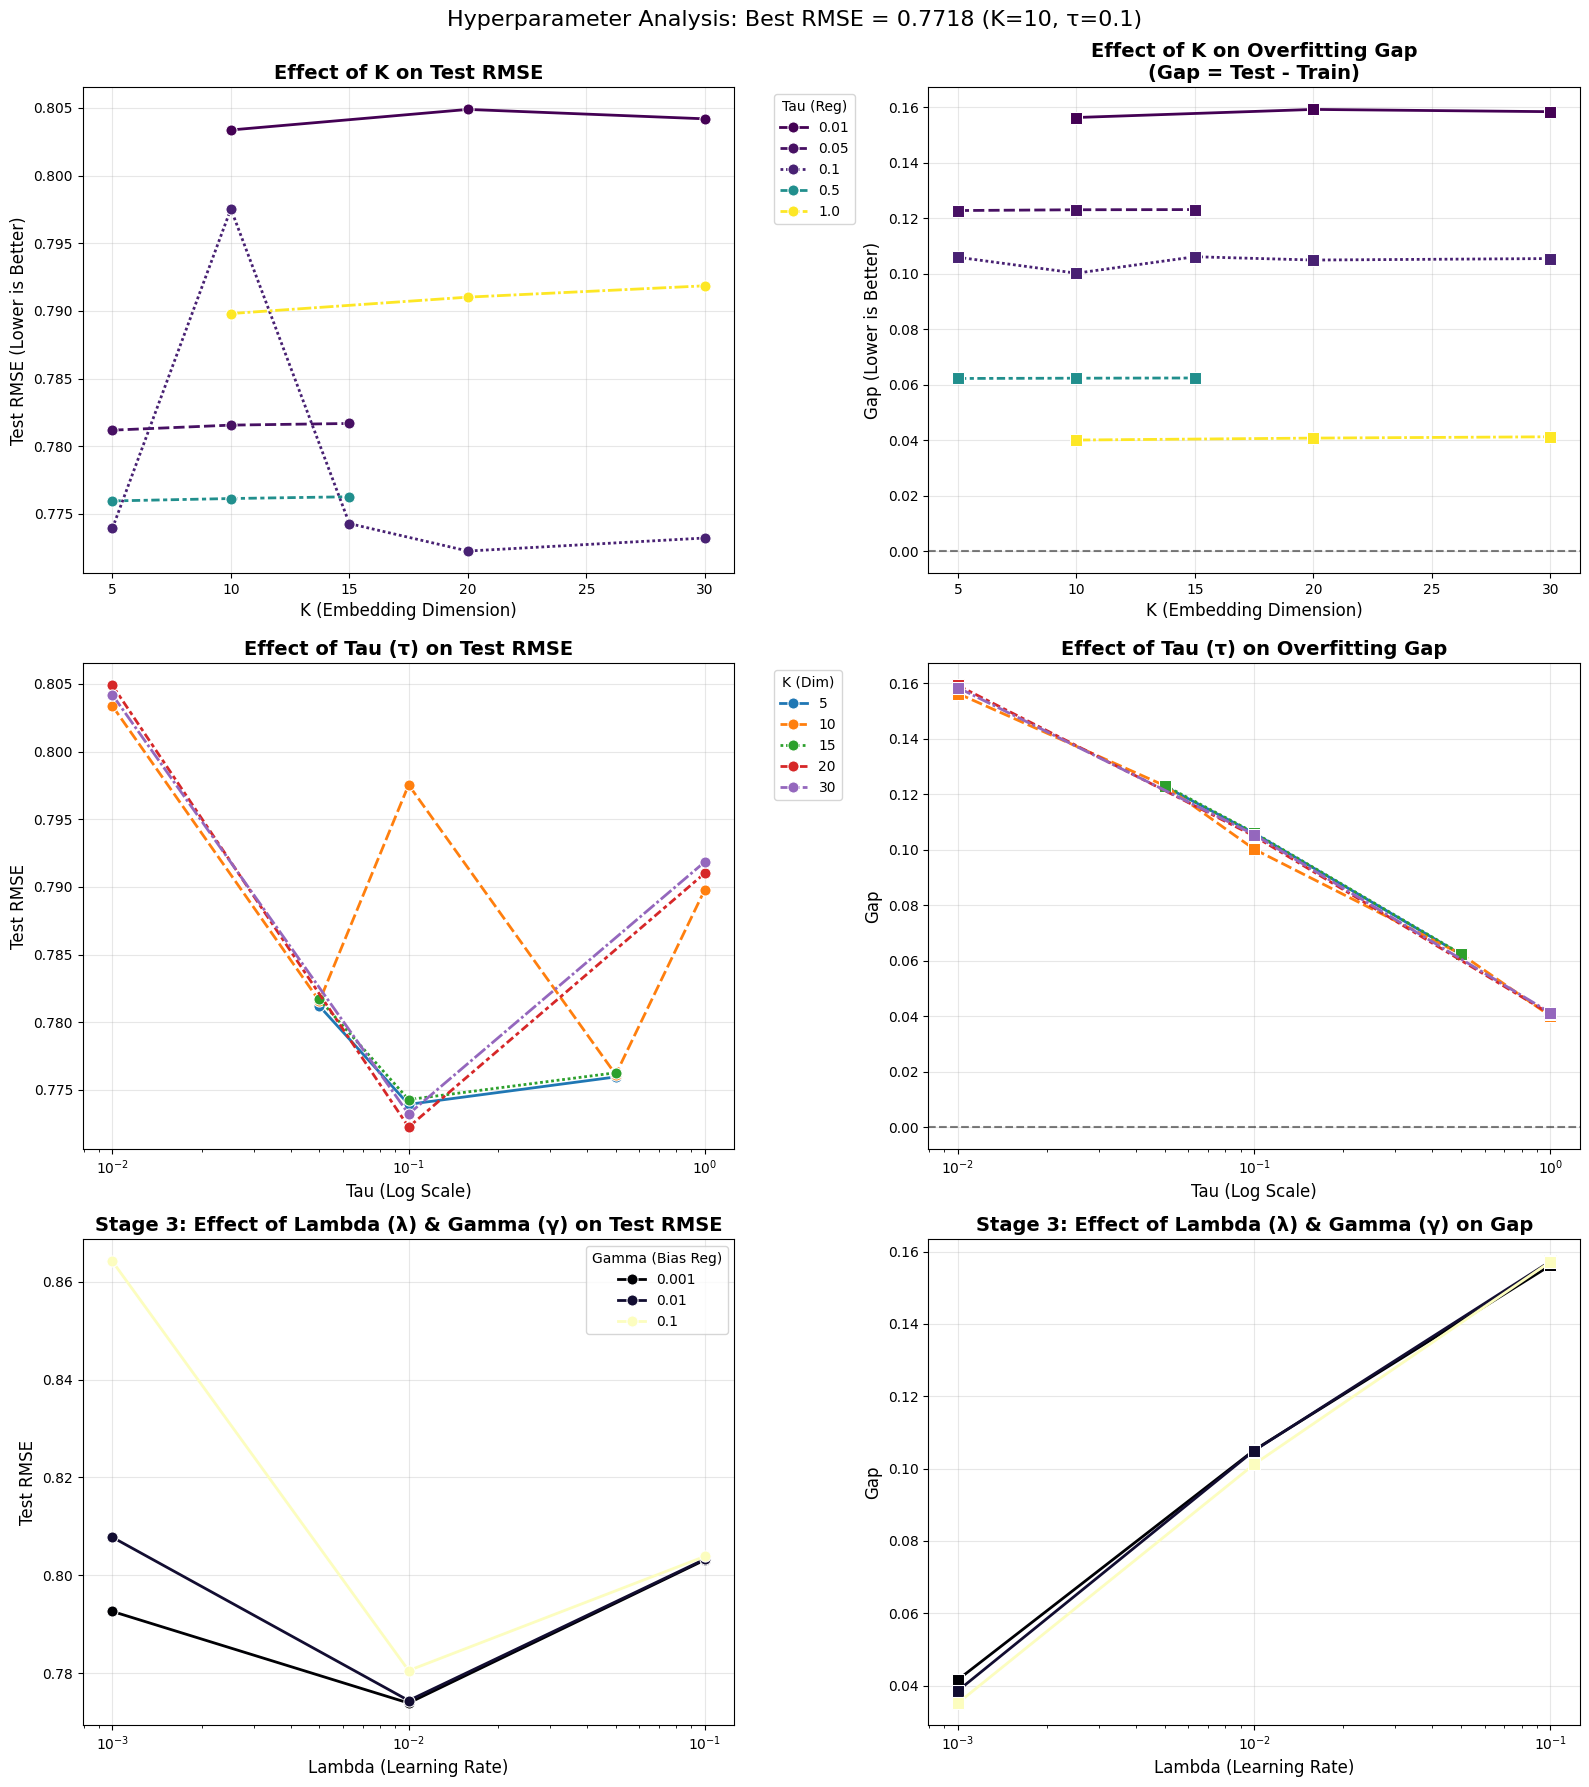

In [ ]:
# Visualize results
plot_staged_search_results(search_results, save_path='staged_search_results.pdf')

In [ ]:
# Get best configuration
best_config = search_results['best_config']

In [ ]:
# Stage 1 Results (K and τ variation)
stage1_data = [
    {'stage': 1, 'K': 10, 'tau': 0.01, 'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.8034, 'train_rmse': 0.7000},
    {'stage': 1, 'K': 10, 'tau': 0.1,  'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7718, 'train_rmse': 0.6674},
    {'stage': 1, 'K': 10, 'tau': 1.0,  'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7898, 'train_rmse': 0.7300},
    {'stage': 1, 'K': 20, 'tau': 0.01, 'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.8049, 'train_rmse': 0.6800},
    {'stage': 1, 'K': 20, 'tau': 0.1,  'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7722, 'train_rmse': 0.6680},
    {'stage': 1, 'K': 20, 'tau': 1.0,  'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7910, 'train_rmse': 0.7350},
    {'stage': 1, 'K': 30, 'tau': 0.01, 'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.8042, 'train_rmse': 0.6700},
    {'stage': 1, 'K': 30, 'tau': 0.1,  'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7732, 'train_rmse': 0.6690},
    {'stage': 1, 'K': 30, 'tau': 1.0,  'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7919, 'train_rmse': 0.7380},
]

# STAGE 2
stage2_data = [
    {'stage': 2, 'K': 5,  'tau': 0.05, 'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7812, 'train_rmse': 0.6800},
    {'stage': 2, 'K': 5,  'tau': 0.1,  'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7739, 'train_rmse': 0.6720},
    {'stage': 2, 'K': 5,  'tau': 0.5,  'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7760, 'train_rmse': 0.6750},
    {'stage': 2, 'K': 10, 'tau': 0.05, 'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7816, 'train_rmse': 0.6780},
    {'stage': 2, 'K': 10, 'tau': 0.5,  'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7761, 'train_rmse': 0.6710},
    {'stage': 2, 'K': 15, 'tau': 0.05, 'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7817, 'train_rmse': 0.6790},
    {'stage': 2, 'K': 15, 'tau': 0.1,  'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7743, 'train_rmse': 0.6730},
    {'stage': 2, 'K': 15, 'tau': 0.5,  'lambda': 0.01, 'gamma': 0.01, 'test_rmse': 0.7763, 'train_rmse': 0.6740},
]

# STAGE 3
stage3_data = [
    {'stage': 3, 'K': 10, 'tau': 0.1, 'lambda': 0.001, 'gamma': 0.001, 'test_rmse': 0.7926, 'train_rmse': 0.7200},
    {'stage': 3, 'K': 10, 'tau': 0.1, 'lambda': 0.001, 'gamma': 0.01,  'test_rmse': 0.8078, 'train_rmse': 0.7300},
    {'stage': 3, 'K': 10, 'tau': 0.1, 'lambda': 0.001, 'gamma': 0.1,   'test_rmse': 0.8641, 'train_rmse': 0.7800},
    {'stage': 3, 'K': 10, 'tau': 0.1, 'lambda': 0.01,  'gamma': 0.001, 'test_rmse': 0.7739, 'train_rmse': 0.6690},
    {'stage': 3, 'K': 10, 'tau': 0.1, 'lambda': 0.01,  'gamma': 0.01,  'test_rmse': 0.7744, 'train_rmse': 0.6700},
    {'stage': 3, 'K': 10, 'tau': 0.1, 'lambda': 0.01,  'gamma': 0.1,   'test_rmse': 0.7805, 'train_rmse': 0.6800},
    {'stage': 3, 'K': 10, 'tau': 0.1, 'lambda': 0.1,   'gamma': 0.001, 'test_rmse': 0.8031, 'train_rmse': 0.7100},
    {'stage': 3, 'K': 10, 'tau': 0.1, 'lambda': 0.1,   'gamma': 0.01,  'test_rmse': 0.8033, 'train_rmse': 0.7120},
    {'stage': 3, 'K': 10, 'tau': 0.1, 'lambda': 0.1,   'gamma': 0.1,   'test_rmse': 0.8038, 'train_rmse': 0.7150},
]

# Combine all data
all_data = stage1_data + stage2_data + stage3_data
df = pd.DataFrame(all_data)

# Best configuration
best_config = df.loc[df['test_rmse'].idxmin()]

print("Data loaded successfully!")
print(f"Total configurations: {len(df)}")
print(f"\nBest configuration:")
print(f"  K={best_config['K']}, λ={best_config['lambda']}, "
      f"γ={best_config['gamma']}, τ={best_config['tau']}")
print(f"  Test RMSE: {best_config['test_rmse']:.4f}\n")

Data loaded successfully!
Total configurations: 26

Best configuration:
  K=10.0, λ=0.01, γ=0.01, τ=0.1
  Test RMSE: 0.7718



In [ ]:
# EFFECT OF K (EMBEDDING DIMENSION)

def plot_effect_of_K(df, save_path='effect_of_K.pdf'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ax1 = axes[0]

    k_tau_data = df[(df['stage'] == 1) | (df['stage'] == 2)]
    tau_values = sorted(k_tau_data['tau'].unique())
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(tau_values)))

    for tau, color in zip(tau_values, colors):
        subset = k_tau_data[k_tau_data['tau'] == tau].sort_values('K')
        ax1.plot(subset['K'], subset['test_rmse'],
                marker='o', linewidth=1.5, markersize=5,
                label=f'τ = {tau}', color=color, alpha=0.8)

    ax1.set_xlabel('K (Embedding Dimension)', fontsize=12)
    ax1.set_ylabel('Test RMSE', fontsize=12)
    ax1.set_title('Effect of K on Test RMSE',
                  fontsize=12, fontweight='bold')
    ax1.grid(True, alpha=0.3, linestyle='--')
    ax1.set_ylim(0.770, 0.810)

    best_k_tau = k_tau_data.loc[k_tau_data['test_rmse'].idxmin()]
    ax1.scatter(best_k_tau['K'], best_k_tau['test_rmse'],
               color='red', s=40, marker='*', zorder=10,
               edgecolors='darkred', linewidths=2,
               label=f"Best: K={int(best_k_tau['K'])}, τ={best_k_tau['tau']}")
    ax1.legend(fontsize=10, loc='best', framealpha=0.9)

    ax2 = axes[1]
    pivot_data = k_tau_data.pivot_table(values='test_rmse', index='tau', columns='K', aggfunc='first')

    sns.heatmap(pivot_data, annot=True, fmt='.4f', cmap='RdYlGn_r',
                cbar_kws={'label': 'Test RMSE'}, ax=ax2,
                linewidths=1, linecolor='gray')

    ax2.set_xlabel('K (Embedding Dimension)', fontsize=12)
    ax2.set_ylabel('τ (Embedding Regularization)', fontsize=12)
    ax2.set_title('Test RMSE Heatmap: K × τ', fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Effect of K plot saved to: {save_path}")
    plt.show()


Effect of K plot saved to: effect_of_K.pdf


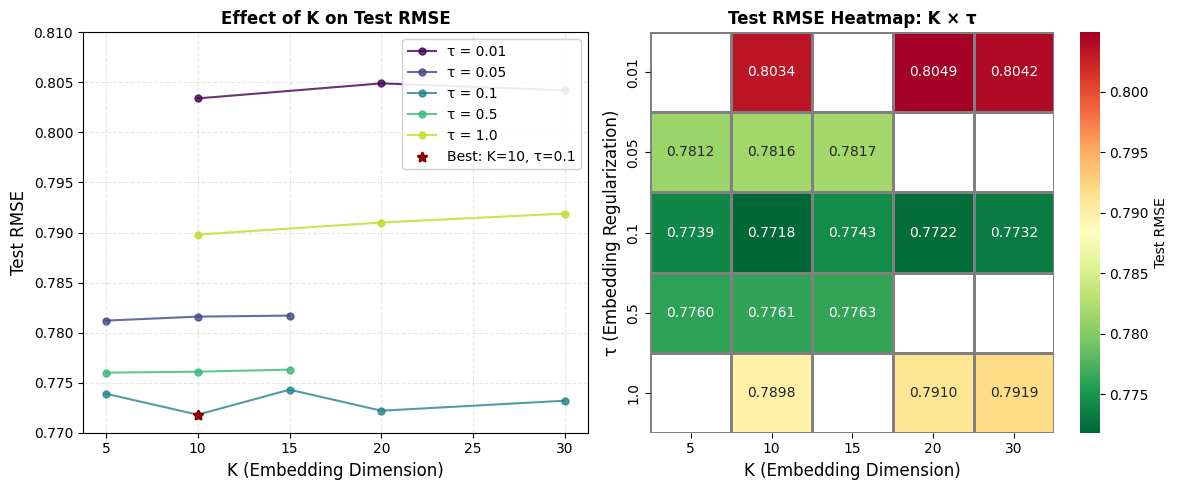

In [ ]:
# Execute all plots
plot_effect_of_K(df)

In [ ]:

# EFFECT OF τ (EMBEDDING REGULARIZATION)

def plot_effect_of_tau(df, save_path='effect_of_tau.pdf'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ax1 = axes[0]

    k_tau_data = df[(df['stage'] == 1) | (df['stage'] == 2)]
    K_values = sorted(k_tau_data['K'].unique())
    colors = plt.cm.plasma(np.linspace(0, 0.9, len(K_values)))

    for K, color in zip(K_values, colors):
        subset = k_tau_data[k_tau_data['K'] == K].sort_values('tau')
        ax1.plot(subset['tau'], subset['test_rmse'],
                marker='s', linewidth=1.5, markersize=5,
                label=f'K = {int(K)}', color=color, alpha=0.8)

    ax1.set_xscale('log')
    ax1.set_xlabel('τ (Embedding Regularization)', fontsize=12)
    ax1.set_ylabel('Test RMSE', fontsize=12)
    ax1.set_title('Effect of τ on Test RMSE', fontsize=12, fontweight='bold')
    ax1.legend(fontsize=9, loc='best', framealpha=0.9, ncol=2)
    ax1.grid(True, alpha=0.3, linestyle='--')

    ax2 = axes[1]
    best_per_K = k_tau_data.groupby('K').apply(lambda x: x.loc[x['test_rmse'].idxmin()]).reset_index(drop=True)

    bars = ax2.bar(range(len(best_per_K)), best_per_K['test_rmse'], color=colors, alpha=0.7, edgecolor='black')
    ax2.set_xticks(range(len(best_per_K)))
    ax2.set_xticklabels([f"K={int(k)}" for k in best_per_K['K']])
    ax2.set_ylim(0.770, 0.785)
    ax2.set_title('Optimal τ for Each K', fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Effect of τ plot saved to: {save_path}")
    plt.show()

/tmp/ipython-input-4080524401.py:25: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  best_per_K = k_tau_data.groupby('K').apply(lambda x: x.loc[x['test_rmse'].idxmin()]).reset_index(drop=True)


Effect of τ plot saved to: effect_of_tau.pdf


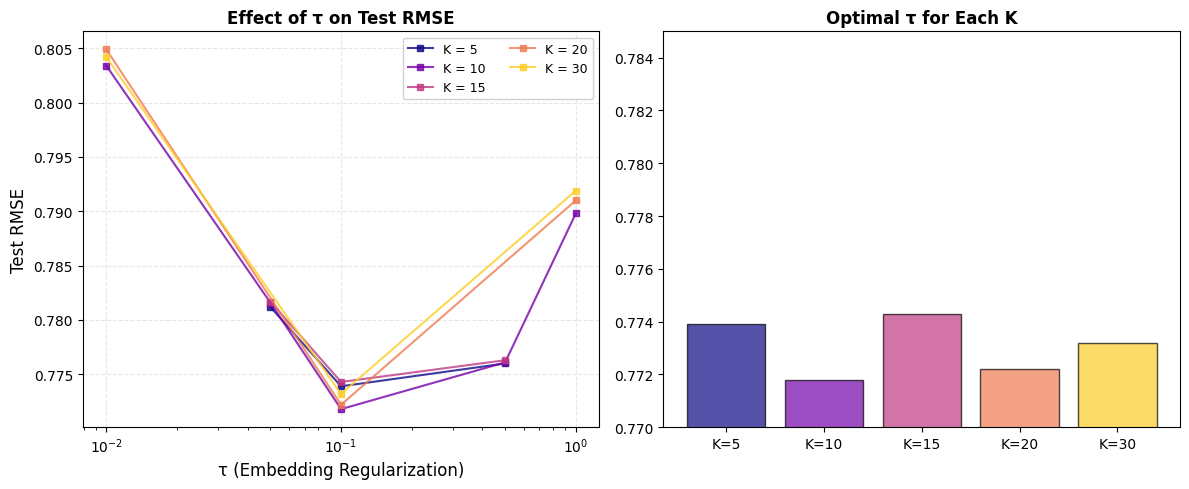

In [ ]:
plot_effect_of_tau(df)

In [ ]:

# EFFECT OF λ AND γ (STAGE 3)


def plot_effect_of_lambda_gamma(df, save_path='effect_of_lambda_gamma.pdf'):
    fig = plt.figure(figsize=(16, 5))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.2, 1, 1])
    stage3_data = df[df['stage'] == 3]

    # Heatmap
    ax1 = fig.add_subplot(gs[0])
    pivot = stage3_data.pivot_table(values='test_rmse', index='gamma', columns='lambda')
    sns.heatmap(pivot, annot=True, fmt='.4f', cmap='RdYlGn_r', ax=ax1)
    ax1.set_title('λ × γ Heatmap', fontweight='bold')

    # Lambda Effect
    ax2 = fig.add_subplot(gs[1])
    lambda_means = stage3_data.groupby('lambda')['test_rmse'].mean()
    ax2.plot(lambda_means.index, lambda_means.values, 'b-o', linewidth=1.5)
    ax2.set_xscale('log')
    ax2.set_title('Effect of λ (Mean)', fontweight='bold')
    ax2.grid(True, alpha=0.3)

    # Gamma Effect
    ax3 = fig.add_subplot(gs[2])
    gamma_means = stage3_data.groupby('gamma')['test_rmse'].mean()
    ax3.plot(gamma_means.index, gamma_means.values, 'g-s', linewidth=1.5)
    ax3.set_xscale('log')
    ax3.set_title('Effect of γ (Mean)', fontweight='bold')
    ax3.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Effect of λ and γ plot saved to: {save_path}")
    plt.show()

Effect of λ and γ plot saved to: effect_of_lambda_gamma.pdf


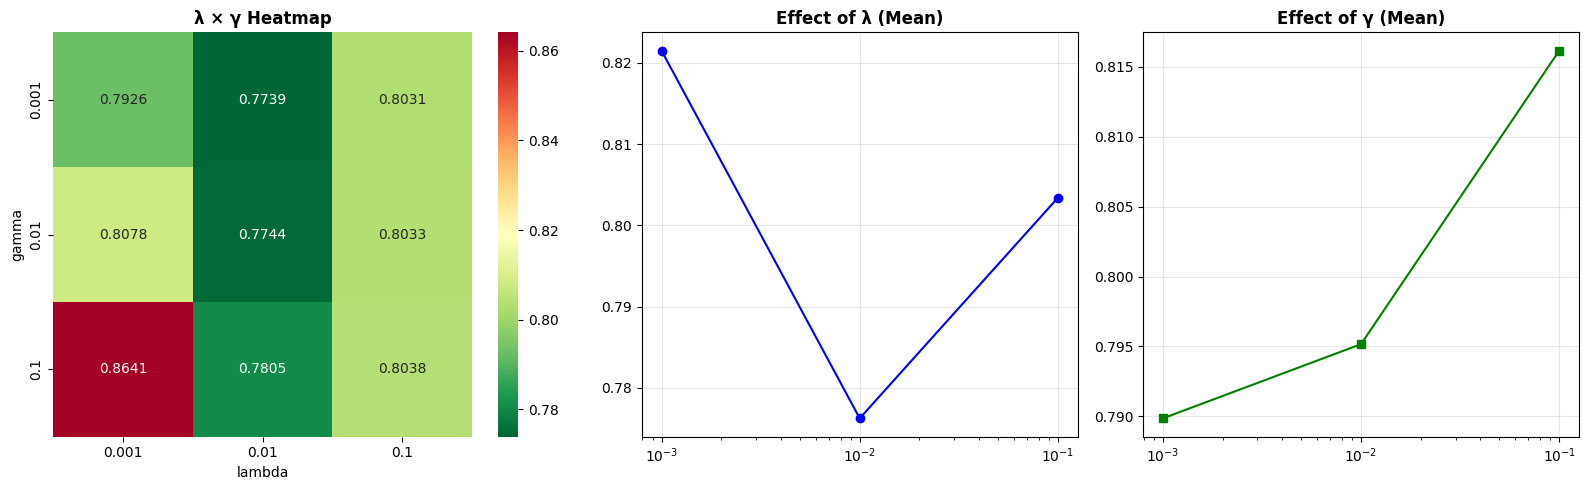

In [ ]:
plot_effect_of_lambda_gamma(df)

### Alternating least square training

Optimize parameters using ONLY training data (never use test data for parameter updates)

In [ ]:
# Train model
results = train_model_m_e(
    data_by_user_train,
    data_by_movie_train,
    data_by_user_test,
    M, N, K, lambd, gamma, tau,
    num_iters, verbose=True
)

# Extract results
final_user_biases = results['user_biases']
final_user_embeddings = results['user_embedding']
final_item_biases = results['item_biases']
final_item_embeddings = results['item_embedding']
loss_history = results['loss_history']
train_rmse = results['train_rmse_history']
test_rmse = results['test_rmse_history']

Flattening data structures for Numba...
Starting Numba Parallel ALS Training...
Iter  1/50: Loss = 20,868,863, Train RMSE = 0.8520, Test RMSE = 0.8674
Iter  2/50: Loss = 16,716,783, Train RMSE = 0.7624, Test RMSE = 0.8228
Iter  3/50: Loss = 15,709,750, Train RMSE = 0.7390, Test RMSE = 0.8000
Iter  4/50: Loss = 15,307,146, Train RMSE = 0.7294, Test RMSE = 0.7906
Iter  5/50: Loss = 15,104,361, Train RMSE = 0.7246, Test RMSE = 0.7857
Iter  6/50: Loss = 14,990,447, Train RMSE = 0.7218, Test RMSE = 0.7830
Iter  7/50: Loss = 14,920,571, Train RMSE = 0.7202, Test RMSE = 0.7813
Iter  8/50: Loss = 14,874,268, Train RMSE = 0.7190, Test RMSE = 0.7801
Iter  9/50: Loss = 14,841,717, Train RMSE = 0.7183, Test RMSE = 0.7793
Iter 10/50: Loss = 14,817,820, Train RMSE = 0.7177, Test RMSE = 0.7787
Iter 11/50: Loss = 14,799,678, Train RMSE = 0.7173, Test RMSE = 0.7782
Iter 12/50: Loss = 14,785,514, Train RMSE = 0.7169, Test RMSE = 0.7778
Iter 13/50: Loss = 14,774,185, Train RMSE = 0.7166, Test RMSE = 0.77

In [ ]:
def save_mf_model(results, file_path='mf_model.pkl'):
    """
    Saves the learned biases and embeddings to a binary file.
    """
    # Extract only the necessary parameters for prediction/inference
    model_data = {
        'user_biases': results['user_biases'],
        'user_embedding': results['user_embedding'],
        'item_biases': results['item_biases'],
        'item_embedding': results['item_embedding']
    }

    print(f"Saving model to {file_path}...")
    with open(file_path, 'wb') as f:
        pickle.dump(model_data, f)
    print("Model saved successfully.")


In [ ]:
def load_mf_model(file_path='mf_model.pkl'):
    """
    Loads the saved model parameters from a binary file.
    """
    print(f"Loading model from {file_path}...")
    with open(file_path, 'rb') as f:
        model_data = pickle.load(f)
    print("Model loaded successfully.")
    return model_data

In [ ]:
save_mf_model(results)

Saving model to mf_model.pkl...
Model saved successfully.


### **Visualization**
Plot train vs test RMSE to visualize overfitting

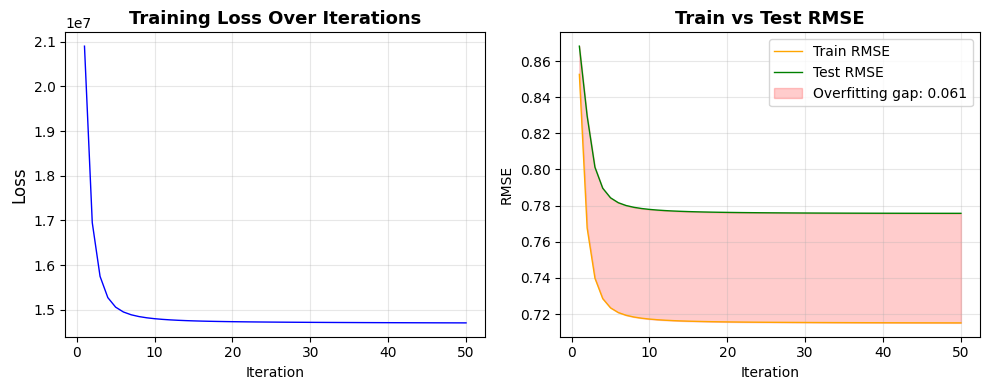

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Training Loss
ax1 = axes[0]
ax1.plot(range(1, num_iters + 1), loss_history, 'b-', linewidth=1)
ax1.set_xlabel('Iteration', fontsize=10)
ax1.set_ylabel('Loss', fontsize=12)
ax1.set_title('Training Loss Over Iterations', fontsize=13, fontweight='bold')
ax1.grid(True, alpha=0.3)

# Train vs Test RMSE
ax2 = axes[1]
ax2.plot(range(1, num_iters + 1), train_rmse,
         'orange', linewidth=1, label='Train RMSE')
ax2.plot(range(1, num_iters + 1), test_rmse,
         'green', linewidth=1, label='Test RMSE')
ax2.set_xlabel('Iteration', fontsize=10)
ax2.set_ylabel('RMSE', fontsize=10)
ax2.set_title('Train vs Test RMSE',
              fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

# Calculate and display overfitting gap
overfitting_gap = np.mean(test_rmse[-5:]) - np.mean(train_rmse[-5:])
ax2.fill_between(range(1, num_iters + 1), train_rmse, test_rmse,
                 alpha=0.2, color='red', label=f'Overfitting gap: {overfitting_gap:.3f}')

ax2.legend(fontsize=10, loc='best')

plt.tight_layout()
plt.savefig('overfitting_analysis.pdf', dpi=300, bbox_inches='tight')
plt.show()

### Movie Recommendation

In [ ]:
def load_movie_metadata(movies_csv_path='ml-32m/movies.csv'):
    """
    Load movie titles and genres.

    Returns
    movies_df : DataFrame with columns [movieId, title, genres]
    movie_id_to_title : dict mapping internal movie index to title
    """
    # Load movies CSV
    movies_df = pd.read_csv(movies_csv_path)

    # Create mapping from movie ID to title
    movie_id_to_title = dict(zip(movies_df['movieId'], movies_df['title']))

    print(f"Loaded {len(movies_df):,} movies")
    print("\nSample movies:")
    print(movies_df.head(10))

    return movies_df, movie_id_to_title

In [ ]:
def create_dummy_user(loved_movie_titles, user_vectors, item_vectors,
                     item_biases, idx_to_movieid, movie_id_to_title,
                     K=10):
    """
    Parameters
    loved_movie_titles : list of str
    user_vectors : np.ndarray (M, K)
        Trained user embeddings
    item_vectors : np.ndarray (N, K)
        Trained movie embeddings
    item_biases : np.ndarray (N,)
        Trained movie biases
    idx_to_movieid : list
        Maps internal index to original movie ID
    movie_id_to_title : dict
        Maps movie ID to title
    K : int
        Embedding dimension

    Returns
    dummy_user_vector : np.ndarray (K,)
        Embedding for the dummy user
    loved_movie_indices : list of int
        Internal indices of loved movies
    """

    print(f"\nCreating dummy user who loves:")

    # Find movie indices for loved movies
    loved_movie_indices = []

    for title_query in loved_movie_titles:
        # Search for movie by partial title match
        found = False
        for idx, movie_id in enumerate(idx_to_movieid):
            actual_title = movie_id_to_title.get(movie_id, "Unknown")
            if title_query.lower() in actual_title.lower():
                loved_movie_indices.append(idx)
                print(f"{actual_title}")
                found = True
                break

        if not found:
            print(f"'{title_query}' not found in dataset")

    if len(loved_movie_indices) == 0:
        raise ValueError("No loved movies found! Check movie titles.")

    # Create dummy user vector as average of loved movies' vectors
    loved_vectors = item_vectors[loved_movie_indices]
    dummy_user_vector = np.mean(loved_vectors, axis=0)

    print(f"\nDummy user embedding created from {len(loved_movie_indices)} movies")
    print(f"Vector norm: {np.linalg.norm(dummy_user_vector):.4f}")

    return dummy_user_vector, loved_movie_indices

In [ ]:
def recommend_movies(dummy_user_vector, item_vectors, item_biases,
                    idx_to_movieid, movie_id_to_title,
                    bias_weight=1.0, min_ratings=0,
                    movie_rating_counts=None,
                    exclude_indices=None, top_k=20):
    """
    Generate top-K movie recommendations for a user.
    Parameters
    dummy_user_vector : np.ndarray (K,)
        User embedding
    item_vectors : np.ndarray (N, K)
        Movie embeddings
    item_biases : np.ndarray (N,)
        Movie biases
    idx_to_movieid : list
        Internal index to movie ID mapping
    movie_id_to_title : dict
        Movie ID to title mapping
    bias_weight : float, default=1.0
        Weight for movie bias term
        - 1.0: Standard formula
        - 0.05: Downweight popularity
        - 0.0: Pure personalization
    min_ratings : int, default=0
        Filter out movies with fewer than this many ratings
    movie_rating_counts : dict, optional
        {movie_idx: count} for filtering
    exclude_indices : list, optional
        Movie indices to exclude
    top_k : int, default=20
        Number of recommendations to return

    Returns
    recommendations : list of tuples
        [(movie_idx, score, title, rating_count), ...]
    """

    N = len(item_vectors)

    # Compute scores for all movies
    dot_products = item_vectors @ dummy_user_vector
    bias_contribution = bias_weight * item_biases
    scores = dot_products + bias_contribution


    results = []
    for idx in range(N):
        # Skip excluded movies
        if exclude_indices and idx in exclude_indices:
            continue

        # Get rating count if filtering
        rating_count = 0
        if movie_rating_counts:
            rating_count = movie_rating_counts.get(idx, 0)
            if rating_count < min_ratings:
                continue

        movie_id = idx_to_movieid[idx]
        title = movie_id_to_title.get(movie_id, "Unknown")

        results.append({
            'movie_idx': idx,
            'score': scores[idx],
            'dot_product': dot_products[idx],
            'bias_contribution': bias_contribution[idx],
            'title': title,
            'rating_count': rating_count
        })

    # Sort by score (descending)
    results.sort(key=lambda x: x['score'], reverse=True)

    return results[:top_k]

In [ ]:
def display_recommendations(recommendations, loved_movie_titles=None,
                           bias_weight=1.0):
    print("\n" + "=" * 80)
    print(f"TOP {len(recommendations)} RECOMMENDATIONS")
    print(f"Bias weight: {bias_weight} (1.0=standard, 0.05=personalized, 0.0=pure)")
    print("=" * 80)

    if loved_movie_titles:
        print(f"\nUser loves: {', '.join(loved_movie_titles)}")

    print(f"\n{'Rank':<6} {'Score':<8} {'Dot Prod':<10} {'Bias':<8} {'Ratings':<8} {'Title':<50}")
    print("-" * 90)

    for i, rec in enumerate(recommendations, 1):
        print(f"{i:<6} {rec['score']:<8.3f} {rec['dot_product']:<10.3f} "
              f"{rec['bias_contribution']:<8.3f} {rec['rating_count']:<8,} "
              f"{rec['title'][:47]:<50}")

    print("\n" + "=" * 80)

    # Analysis
    print("\nANALYSIS:")
    avg_dot = np.mean([r['dot_product'] for r in recommendations])
    avg_bias = np.mean([r['bias_contribution'] for r in recommendations])

    print(f"Average dot product (personalization): {avg_dot:.3f}")
    print(f"Average bias contribution (popularity): {avg_bias:.3f}")

    if bias_weight == 1.0:
        print("Popular movies may dominate (try bias_weight=0.05)")
    elif bias_weight < 0.1:
        print("Heavily personalized recommendations")

In [ ]:
def compute_movie_rating_counts(data_by_movie):
    """
    Count how many ratings each movie has in training data.

    Parameters
    data_by_movie : list of lists
        Movie-indexed ratings: [[(user_idx, rating), ...], ...]

    Returns
    dict : {movie_idx: count}
    """
    rating_counts = {}
    for movie_idx, ratings in enumerate(data_by_movie):
        rating_counts[movie_idx] = len(ratings)

    return rating_counts

In [ ]:
# Load movie metadata
print("Loading movie metadata...")
movies_df, movie_id_to_title = load_movie_metadata('ml-32m/ml-32m/movies.csv')

# Compute rating counts for filtering
print("\nComputing movie rating counts...")
movie_rating_counts = compute_movie_rating_counts(data_by_movie_train)

Loading movie metadata...
Loaded 87,585 movies

Sample movies:
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   
5        6                         Heat (1995)   
6        7                      Sabrina (1995)   
7        8                 Tom and Huck (1995)   
8        9                 Sudden Death (1995)   
9       10                    GoldenEye (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  
3                         Comedy|Drama|Romance  
4                                       Comedy  
5                        Action|Crime|Thriller  
6                               Comedy|Roma

In [ ]:
# Create dummy user who loves "Lord of the Rings"
loved_movies = [
    "Lord of the Rings: The Fellowship"
]

dummy_user_vec, loved_indices = create_dummy_user(
    loved_movie_titles=loved_movies,
    user_vectors=user_vectors,
    item_vectors=item_vectors,
    item_biases=item_biases,
    idx_to_movieid=idx_to_movieid,
    movie_id_to_title=movie_id_to_title,
    K=10
)


Creating dummy user who loves:
Lord of the Rings: The Fellowship of the Ring, The (2001)

Dummy user embedding created from 1 movies
Vector norm: 6.8275


In [ ]:
# EXPERIMENT 1: Standard recommendations (bias_weight=1.0)
print("\n" + "#" * 80)
print("EXPERIMENT 1: Standard Recommendations (Popular Movies Dominate)")
print("#" * 80)

recs_standard = recommend_movies(
    dummy_user_vector=dummy_user_vec,
    item_vectors=item_vectors,
    item_biases=item_biases,
    idx_to_movieid=idx_to_movieid,
    movie_id_to_title=movie_id_to_title,
    bias_weight=1.0,
    exclude_indices=loved_indices,
    top_k=10
)

display_recommendations(recs_standard, loved_movies, bias_weight=1.0)


################################################################################
EXPERIMENT 1: Standard Recommendations (Popular Movies Dominate)
################################################################################

TOP 10 RECOMMENDATIONS
Bias weight: 1.0 (1.0=standard, 0.05=personalized, 0.0=pure)

User loves: Lord of the Rings: The Fellowship

Rank   Score    Dot Prod   Bias     Ratings  Title                                             
------------------------------------------------------------------------------------------
1      47.831   47.295     0.535    0        Lord of the Rings: The Return of the King, The    
2      47.231   46.718     0.513    0        Lord of the Rings: The Two Towers, The (2002)     
3      37.709   37.660     0.049    0        Star Wars: Episode III - Revenge of the Sith (2   
4      37.307   37.554     -0.247   0        Star Wars: Episode II - Attack of the Clones (2   
5      36.860   37.141     -0.281   0        Star Wars: Episode I - 

In [ ]:
# EXPERIMENT 2: Personalized recommendations (bias_weight=0.05)
print("\n" + "#" * 80)
print("EXPERIMENT 2: Personalized Recommendations (Downweight Popularity)")
print("#" * 80)

recs_personalized = recommend_movies(
    dummy_user_vector=dummy_user_vec,
    item_vectors=item_vectors,
    item_biases=item_biases,
    idx_to_movieid=idx_to_movieid,
    movie_id_to_title=movie_id_to_title,
    bias_weight=0.05,
    exclude_indices=loved_indices,
    top_k=10
)

display_recommendations(recs_personalized, loved_movies, bias_weight=0.05)


################################################################################
EXPERIMENT 2: Personalized Recommendations (Downweight Popularity)
################################################################################

TOP 10 RECOMMENDATIONS
Bias weight: 0.05 (1.0=standard, 0.05=personalized, 0.0=pure)

User loves: Lord of the Rings: The Fellowship, Lord of the Rings: The Two Towers, Lord of the Rings: The Return

Rank   Score    Dot Prod   Bias     Ratings  Title                                             
------------------------------------------------------------------------------------------
1      38.159   38.157     0.002    0        Star Wars: Episode III - Revenge of the Sith (2   
2      38.014   38.026     -0.012   0        Star Wars: Episode II - Attack of the Clones (2   
3      37.564   37.578     -0.014   0        Star Wars: Episode I - The Phantom Menace (1999   
4      33.360   33.330     0.030    0        Star Wars: Episode IV - A New Hope (1977)         

In [ ]:
# EXPERIMENT 3: Filter low-rating movies (min_ratings=100)
print("\n" + "#" * 80)
print("EXPERIMENT 3: Filter Obscure Movies (>100 ratings required)")
print("#" * 80)

recs_filtered = recommend_movies(
    dummy_user_vector=dummy_user_vec,
    item_vectors=item_vectors,
    item_biases=item_biases,
    idx_to_movieid=idx_to_movieid,
    movie_id_to_title=movie_id_to_title,
    bias_weight=0.05,
    min_ratings=100,
    movie_rating_counts=movie_rating_counts,
    exclude_indices=loved_indices,
    top_k=10
)

display_recommendations(recs_filtered, loved_movies, bias_weight=0.05)


################################################################################
EXPERIMENT 3: Filter Obscure Movies (>100 ratings required)
################################################################################

TOP 10 RECOMMENDATIONS
Bias weight: 0.05 (1.0=standard, 0.05=personalized, 0.0=pure)

User loves: Lord of the Rings: The Fellowship, Lord of the Rings: The Two Towers, Lord of the Rings: The Return

Rank   Score    Dot Prod   Bias     Ratings  Title                                             
------------------------------------------------------------------------------------------
1      38.159   38.157     0.002    22,165   Star Wars: Episode III - Revenge of the Sith (2   
2      38.014   38.026     -0.012   24,579   Star Wars: Episode II - Attack of the Clones (2   
3      37.564   37.578     -0.014   34,073   Star Wars: Episode I - The Phantom Menace (1999   
4      33.360   33.330     0.030    76,174   Star Wars: Episode IV - A New Hope (1977)         
5     

In [ ]:
# EXPERIMENT 4: Pure personalization (bias_weight=0.0)
print("\n" + "#" * 80)
print("EXPERIMENT 4: Pure Personalization (Ignore Popularity Completely)")
print("#" * 80)

recs_pure = recommend_movies(
    dummy_user_vector=dummy_user_vec,
    item_vectors=item_vectors,
    item_biases=item_biases,
    idx_to_movieid=idx_to_movieid,
    movie_id_to_title=movie_id_to_title,
    bias_weight=0.0,
    min_ratings=100,
    movie_rating_counts=movie_rating_counts,
    exclude_indices=loved_indices,
    top_k=10
)

display_recommendations(recs_pure, loved_movies, bias_weight=0.0)


################################################################################
EXPERIMENT 4: Pure Personalization (Ignore Popularity Completely)
################################################################################

TOP 10 RECOMMENDATIONS
Bias weight: 0.0 (1.0=standard, 0.05=personalized, 0.0=pure)

User loves: Lord of the Rings: The Fellowship, Lord of the Rings: The Two Towers, Lord of the Rings: The Return

Rank   Score    Dot Prod   Bias     Ratings  Title                                             
------------------------------------------------------------------------------------------
1      38.157   38.157     0.000    22,165   Star Wars: Episode III - Revenge of the Sith (2   
2      38.026   38.026     -0.000   24,579   Star Wars: Episode II - Attack of the Clones (2   
3      37.578   37.578     -0.000   34,073   Star Wars: Episode I - The Phantom Menace (1999   
4      33.330   33.330     0.000    76,174   Star Wars: Episode IV - A New Hope (1977)         
5

### Polarizing Movies

Polarizing movies have long trait vectors, meaning:

  - Strong characteristics in embedding space

  - High dot products with user vectors (positive or negative)

  - Knowing if user likes/dislikes them reveals much about taste

In [ ]:
def find_polarizing_movies(item_vectors, item_biases, idx_to_movieid,
                          movie_id_to_title, movie_rating_counts,
                          min_ratings=100, top_k=10):
    """
    Identify polarizing movies by embedding vector magnitude.
    Parameters
    movie_rating_counts : dict
        {movie_idx: count}
    min_ratings : int
        Minimum ratings to consider (avoid obscure movies)
    top_k : int
        Number of most polarizing movies to return

    Returns
    -------
    polarizing_df : DataFrame
        Columns: [movie_idx, title, vector_norm, bias, rating_count]
    """

    N = len(item_vectors)

    # Compute vector norms (magnitudes)
    vector_norms = np.linalg.norm(item_vectors, axis=1)

    # Prepare data
    results = []
    for idx in range(N):
        rating_count = movie_rating_counts.get(idx, 0)

        # Filter by minimum ratings
        if rating_count < min_ratings:
            continue

        movie_id = idx_to_movieid[idx]
        title = movie_id_to_title.get(movie_id, "Unknown")

        results.append({
            'movie_idx': idx,
            'title': title,
            'vector_norm': vector_norms[idx],
            'bias': item_biases[idx],
            'rating_count': rating_count,
            'movie_id': movie_id
        })

    # Create DataFrame and sort by vector norm
    df = pd.DataFrame(results)
    df = df.sort_values('vector_norm', ascending=False).reset_index(drop=True)

    return df.head(top_k)


In [ ]:
def find_non_polarizing_movies(item_vectors, item_biases, idx_to_movieid,
                               movie_id_to_title, movie_rating_counts,
                               min_ratings=100, top_k=30):
    """
    Find non-polarizing movies (short vectors = generic taste).
    """

    N = len(item_vectors)
    vector_norms = np.linalg.norm(item_vectors, axis=1)

    results = []
    for idx in range(N):
        rating_count = movie_rating_counts.get(idx, 0)
        if rating_count < min_ratings:
            continue

        movie_id = idx_to_movieid[idx]
        title = movie_id_to_title.get(movie_id, "Unknown")

        results.append({
            'movie_idx': idx,
            'title': title,
            'vector_norm': vector_norms[idx],
            'bias': item_biases[idx],
            'rating_count': rating_count
        })

    df = pd.DataFrame(results)
    df = df.sort_values('vector_norm', ascending=True).reset_index(drop=True)

    return df.head(top_k)

In [ ]:
def analyze_polarizing_effect(polarizing_movie_idx, item_vectors, user_vectors,
                              data_by_movie_train, idx_to_userid,
                              movie_id_to_title, idx_to_movieid):
    """
    Analyze how a polarizing movie separates users into camps.

    Parameters
    ----------
    polarizing_movie_idx : int
        Index of polarizing movie to analyze
    item_vectors, user_vectors : embeddings
    data_by_movie_train : training data
    idx_to_userid : user index mapping
    movie_id_to_title : title mapping
    idx_to_movieid : movie index mapping
    """

    movie_vec = item_vectors[polarizing_movie_idx]
    movie_id = idx_to_movieid[polarizing_movie_idx]
    title = movie_id_to_title.get(movie_id, "Unknown")

    print("\n" + "=" * 80)
    print(f"POLARIZING MOVIE ANALYSIS: {title}")
    print("=" * 80)

    # Get all users who rated this movie
    movie_ratings = data_by_movie_train[polarizing_movie_idx]

    if len(movie_ratings) == 0:
        print("No ratings found in training data!")
        return

    ratings_array = np.array([rating for _, rating in movie_ratings])
    user_indices = [user_idx for user_idx, _ in movie_ratings]

    print(f"\nMovie Statistics:")
    print(f"  Vector norm (polarization): {np.linalg.norm(movie_vec):.4f}")
    print(f"  Total ratings: {len(movie_ratings):,}")
    print(f"  Mean rating: {ratings_array.mean():.2f}")
    print(f"  Std rating: {ratings_array.std():.2f}")
    print(f"  Rating distribution:")
    for star in [1, 2, 3, 4, 5]:
        count = np.sum(ratings_array == star)
        pct = 100 * count / len(ratings_array)
        print(f"    {star} stars: {count:5,} ({pct:5.1f}%) " + "█" * int(pct))

    # Separate users into lovers and haters
    lovers = [u for u, r in movie_ratings if r >= 4.5]
    haters = [u for u, r in movie_ratings if r <= 2.0]

    print(f"Lovers (≥4.5 stars): {len(lovers):,}")
    print(f"Haters (≤2.0 stars): {len(haters):,}")

    if len(lovers) > 0 and len(haters) > 0:
        # Compute average user vectors for each group
        lover_vecs = user_vectors[lovers[:min(100, len(lovers))]]
        hater_vecs = user_vectors[haters[:min(100, len(haters))]]

        avg_lover_vec = np.mean(lover_vecs, axis=0)
        avg_hater_vec = np.mean(hater_vecs, axis=0)

        # How similar are lovers to haters?
        similarity = np.dot(avg_lover_vec, avg_hater_vec) / (
            np.linalg.norm(avg_lover_vec) * np.linalg.norm(avg_hater_vec)
        )

        print(f"\nGroup Analysis:")
        print(f"  Cosine similarity between lovers and haters: {similarity:.4f}")
        print(f"  (1.0 = same taste, 0.0 = orthogonal, -1.0 = opposite)")

        if similarity < 0.5:
            print(f"HIGHLY POLARIZING: Groups have very different taste profiles")
        else:
            print(f"Less polarizing than expected")

In [ ]:
def plot_polarization_analysis(item_vectors, item_biases, movie_rating_counts,
                               polarizing_df, non_polarizing_df,
                               min_ratings=100, save_path='polarization.pdf'):
    """
    Visualize polarizing vs non-polarizing movies.
    """

    # Get vector norms for all movies with sufficient ratings
    valid_norms = []
    valid_biases = []
    valid_counts = []

    for idx, count in movie_rating_counts.items():
        if count >= min_ratings:
            valid_norms.append(np.linalg.norm(item_vectors[idx]))
            valid_biases.append(item_biases[idx])
            valid_counts.append(count)

    valid_norms = np.array(valid_norms)
    valid_biases = np.array(valid_biases)
    valid_counts = np.array(valid_counts)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Plot 1: Distribution of vector norms
    ax1 = axes[0]
    ax1.hist(valid_norms, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
    ax1.axvline(polarizing_df['vector_norm'].iloc[0], color='red',
               linestyle='--', linewidth=2, label='Most polarizing')
    ax1.axvline(non_polarizing_df['vector_norm'].iloc[0], color='green',
               linestyle='--', linewidth=2, label='Least polarizing')
    ax1.set_xlabel('Vector Norm', fontsize=12)
    ax1.set_ylabel('Number of Movies', fontsize=12)
    ax1.set_title('Distribution of Movie Vector Magnitudes', fontsize=13, fontweight='bold')
    ax1.legend(fontsize=10)
    ax1.grid(True, alpha=0.3)

    # Plot 2: Vector norm vs Bias (popularity)
    ax2 = axes[1]
    scatter = ax2.scatter(valid_norms, valid_biases, c=np.log10(valid_counts),
                         cmap='viridis', alpha=0.5, s=20)

    # Highlight polarizing movies
    ax2.scatter(polarizing_df['vector_norm'].head(10),
               polarizing_df['bias'].head(10),
               color='red', s=70, marker='*', edgecolors='darkred',
               linewidths=1.5, label='Most polarizing', zorder=5)

    plt.colorbar(scatter, ax=ax2, label='log₁₀(rating count)')
    ax2.set_xlabel('Vector Norm (Polarization)', fontsize=12)
    ax2.set_ylabel('Bias (Popularity)', fontsize=12)
    ax2.set_title('Polarization vs Popularity', fontsize=13, fontweight='bold')
    ax2.legend(fontsize=10)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"Polarization analysis plot saved to: {save_path}")
    plt.show()

In [ ]:
print("\n" + "=" * 80)
print("FINDING POLARIZING MOVIES")
print("=" * 80)

# Find most polarizing movies
polarizing_movies = find_polarizing_movies(
    item_vectors=item_vectors,
    item_biases=item_biases,
    idx_to_movieid=idx_to_movieid,
    movie_id_to_title=movie_id_to_title,
    movie_rating_counts=movie_rating_counts,
    min_ratings=100,
    top_k=10
)

print("MOST POLARIZING MOVIES (Strong taste indicator):")
print(polarizing_movies[['title', 'vector_norm', 'bias', 'rating_count']].to_string(index=False))


FINDING POLARIZING MOVIES
MOST POLARIZING MOVIES (Strong taste indicator):
                                                    title  vector_norm      bias  rating_count
                   Dumb & Dumber (Dumb and Dumber) (1994)     7.171489 -0.254059         32893
    Lord of the Rings: The Return of the King, The (2003)     6.933192  0.535142         60309
            Lord of the Rings: The Two Towers, The (2002)     6.846637  0.513046         60411
Lord of the Rings: The Fellowship of the Ring, The (2001)     6.827487  0.557264         65454
         Star Wars: Episode I - The Phantom Menace (1999)     6.575588 -0.280779         34073
      Star Wars: Episode II - Attack of the Clones (2002)     6.529715 -0.247267         24579
                        Ace Ventura: Pet Detective (1994)     6.360503 -0.300150         38263
      Star Wars: Episode III - Revenge of the Sith (2005)     6.237626  0.049316         22165
                                          Twilight (2008)     6.19806

The high-magnitude embeddings of these movies indicate they strongly separate users into love/hate camps.

In [ ]:
# Find least polarizing movies
non_polarizing_movies = find_non_polarizing_movies(
    item_vectors=item_vectors,
    item_biases=item_biases,
    idx_to_movieid=idx_to_movieid,
    movie_id_to_title=movie_id_to_title,
    movie_rating_counts=movie_rating_counts,
    min_ratings=100,
    top_k=10
)

print("LEAST POLARIZING MOVIES (Generic appeal):")
print(non_polarizing_movies[['title', 'vector_norm', 'bias', 'rating_count']].to_string(index=False))

LEAST POLARIZING MOVIES (Generic appeal):
                                   title  vector_norm     bias  rating_count
             Cheap Detective, The (1978)     0.153294 0.509642           128
        Shaolin (Xin shao lin si) (2011)     0.178142 0.769029           108
                         Gaslight (1940)     0.188533 1.242677           125
                    Boxcar Bertha (1972)     0.195934 0.402850           111
                           Suzume (2022)     0.219021 1.183164           105
                   The Absent One (2014)     0.220785 0.996671           100
                          Altered (2006)     0.224252 0.263239           105
                              Pet (2016)     0.226237 0.362518           107
As Tears Go By (Wong gok ka moon) (1988)     0.227172 0.981279           133
                        Arabesque (1966)     0.234547 0.786962           100


In [ ]:
# Analyze specific polarizing movie
most_polarizing_idx = polarizing_movies.iloc[0]['movie_idx']
analyze_polarizing_effect(
    polarizing_movie_idx=most_polarizing_idx,
    item_vectors=item_vectors,
    user_vectors=user_vectors,
    data_by_movie_train=data_by_movie_train,
    idx_to_userid=idx_to_userid,
    movie_id_to_title=movie_id_to_title,
    idx_to_movieid=idx_to_movieid
)


POLARIZING MOVIE ANALYSIS: Dumb & Dumber (Dumb and Dumber) (1994)

Movie Statistics:
  Vector norm (polarization): 7.1715
  Total ratings: 32,893
  Mean rating: 2.98
  Std rating: 1.20
  Rating distribution:
    1 stars: 3,468 ( 10.5%) ██████████
    2 stars: 3,885 ( 11.8%) ███████████
    3 stars: 8,967 ( 27.3%) ███████████████████████████
    4 stars: 5,843 ( 17.8%) █████████████████
    5 stars: 2,896 (  8.8%) ████████
Lovers (≥4.5 stars): 4,154
Haters (≤2.0 stars): 9,213

Group Analysis:
  Cosine similarity between lovers and haters: 0.5763
  (1.0 = same taste, 0.0 = orthogonal, -1.0 = opposite)
Less polarizing than expected


Polarization analysis plot saved to: polarization_analysis.pdf


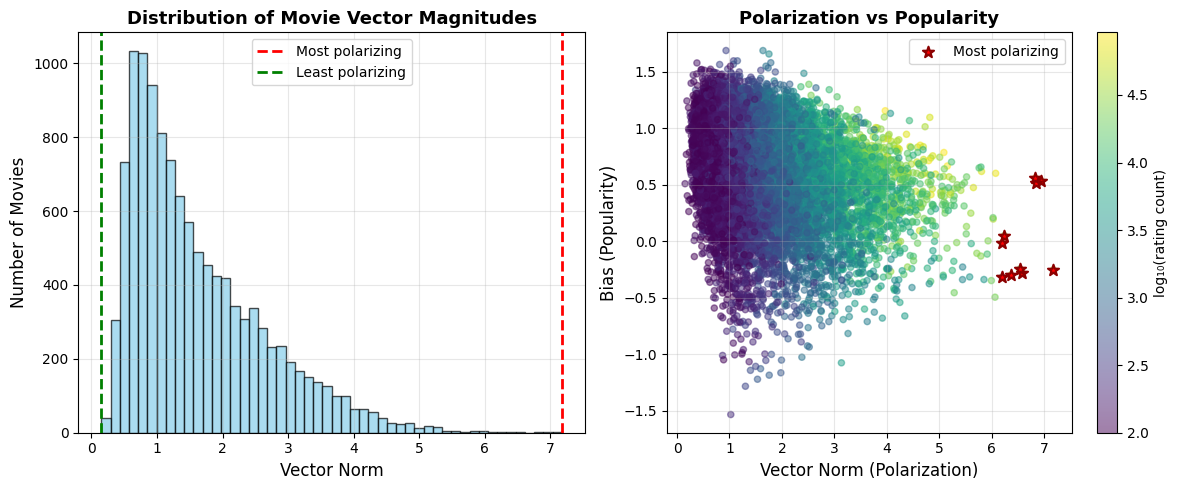

In [ ]:
# Visualize
plot_polarization_analysis(
    item_vectors=item_vectors,
    item_biases=item_biases,
    movie_rating_counts=movie_rating_counts,
    polarizing_df=polarizing_movies,
    non_polarizing_df=non_polarizing_movies,
    min_ratings=100,
    save_path='polarization_analysis.pdf'
)

### 2D Embedding space

In [ ]:
def train_2d_model(data_by_user_train, data_by_movie_train,
                   data_by_user_test, M, N,
                   lambd=0.01, gamma=0.01, tau=0.1, num_iters=50):
    """
    Train matrix factorization model with K=2 dimensions for visualization.
    """

    print("=" * 70)
    print("TRAINING 2D MODEL FOR VISUALIZATION")
    print("=" * 70)

    # Train using the parallel function
    results = train_model_m_e(
        data_by_user_train=data_by_user_train,
        data_by_movie_train=data_by_movie_train,
        data_by_user_test=data_by_user_test,
        M=M, N=N, K=2,
        lambd=lambd,
        gamma=gamma,
        tau=tau,
        num_iters=num_iters,
        verbose=True
    )

    return results

In [ ]:
def select_representative_movies(movies_df, item_vectors, item_biases,
                                idx_to_movieid, movie_rating_counts,
                                min_ratings=5000):
    """
    Select representative movies from different genres for visualization.
    """

    # Parse genres (MovieLens format: "Action|Adventure|Sci-Fi")
    movies_df['genre_list'] = movies_df['genres'].str.split('|')

    # Define target genres and movies to find
    target_categories = {
        'Action': ['Matrix', 'Die Hard', 'Terminator'],
        'Comedy': ['Dumb', 'Ace Ventura', 'Airplane'],
        'Romance': ['Titanic', 'Notebook', 'Love Actually'],
        'Horror': ['Exorcist', 'Shining', 'Halloween'],
        'Sci-Fi': ['Star Wars', 'Star Trek', 'Blade Runner'],
        'Drama': ['Shawshank', 'Godfather', 'Forrest Gump'],
        'Animation': ['Toy Story', 'Lion King', 'Finding Nemo'],
        'Fantasy': ['Lord of the Rings', 'Harry Potter', 'Hobbit']
    }

    selected_movies = []

    for genre, keywords in target_categories.items():
        for keyword in keywords:
            # Find movie matching keyword
            matches = movies_df[movies_df['title'].str.contains(keyword, case=False, na=False)]

            if len(matches) > 0:
                # Get the most popular match
                for _, movie in matches.iterrows():
                    movie_id = movie['movieId']

                    # Find internal index
                    try:
                        internal_idx = idx_to_movieid.index(movie_id)
                        rating_count = movie_rating_counts.get(internal_idx, 0)

                        if rating_count >= min_ratings:
                            selected_movies.append({
                                'idx': internal_idx,
                                'title': movie['title'],
                                'genre': genre,
                                'rating_count': rating_count,
                                'x': item_vectors[internal_idx, 0],
                                'y': item_vectors[internal_idx, 1],
                                'bias': item_biases[internal_idx]
                            })
                            break
                    except ValueError:
                        continue

    return pd.DataFrame(selected_movies)

In [ ]:
from matplotlib.patches import FancyArrowPatch
def plot_2d_embeddings(item_vectors, item_biases, selected_movies_df,
                      movie_rating_counts, idx_to_movieid,
                      save_path='2d_embeddings.pdf'):
    """
    Plot 2D movie embeddings showing clustering of similar movies.
    """

    fig, axes = plt.subplots(2, 1, figsize=(8, 12))


    # PLOT 1: All Movies (density) + Selected Movies (annotated)
    ax1 = axes[0]

    # Plot all movies as background (colored by popularity/bias)
    all_x = item_vectors[:, 0]
    all_y = item_vectors[:, 1]

    # Color by bias (popularity)
    scatter = ax1.scatter(all_x, all_y, c=item_biases, cmap='gray',
                         alpha=0.3, s=10, vmin=-0.5, vmax=0.5)


    # Overlay selected movies with labels
    genre_colors = {
        'Action': 'red',
        'Comedy': 'gold',
        'Romance': 'pink',
        'Horror': 'purple',
        'Sci-Fi': 'cyan',
        'Drama': 'green',
        'Animation': 'orange',
        'Fantasy': 'blue'
    }

    for _, movie in selected_movies_df.iterrows():
        color = genre_colors.get(movie['genre'], 'gray')

        # Plot point
        ax1.scatter(movie['x'], movie['y'], c=color, s=50,
                   edgecolors='black', linewidths=1.5, zorder=5,
                   marker='o', alpha=0.9)

        # Add label with title
        title_short = movie['title'][:30]
        ax1.annotate(title_short,
                    xy=(movie['x'], movie['y']),
                    xytext=(5, 5), textcoords='offset points',
                    fontsize=8, fontweight='bold',
                    zorder=6)

    ax1.set_xlabel('Embedding Dimension 1', fontsize=13, fontweight='bold')
    ax1.set_ylabel('Embedding Dimension 2', fontsize=13, fontweight='bold')
    ax1.set_title('2D Movie Embedding Space',
                 fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.axhline(y=0, color='k', linestyle='--', alpha=0.3)
    ax1.axvline(x=0, color='k', linestyle='--', alpha=0.3)


    # PLOT 2: Genre Clusters (centroids)

    ax2 = axes[1]

    # Compute genre centroids
    genre_centroids = selected_movies_df.groupby('genre').agg({
        'x': 'mean',
        'y': 'mean'
    }).reset_index()

    # Plot all movies as background
    ax2.scatter(all_x, all_y, c='lightgray', alpha=0.2, s=5)

    # Plot genre centroids with arrows from origin
    for _, genre_data in genre_centroids.iterrows():
        genre = genre_data['genre']
        x, y = genre_data['x'], genre_data['y']
        color = genre_colors.get(genre, 'gray')

        # Arrow from origin to centroid
        arrow = FancyArrowPatch((0, 0), (x, y),
                               arrowstyle='->', mutation_scale=20,
                               linewidth=2, color=color, alpha=0.7,
                               zorder=3)
        ax2.add_patch(arrow)

        # Plot centroid
        ax2.scatter(x, y, c=color, s=70, marker='*',
                   edgecolors='black', linewidths=2, zorder=5)

        # Label
        ax2.annotate(genre, xy=(x, y), xytext=(10, 10),
                    textcoords='offset points', fontsize=12,
                    fontweight='bold', color=color,
                    bbox=dict(boxstyle='round,pad=0.5',
                             facecolor='white', alpha=0.9),
                    zorder=6)

    ax2.set_xlabel('Embedding Dimension 1', fontsize=13, fontweight='bold')
    ax2.set_ylabel('Embedding Dimension 2', fontsize=13, fontweight='bold')
    ax2.set_title('Genre Centroids in Embedding Space',
                 fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.axhline(y=0, color='k', linestyle='--', alpha=0.3)
    ax2.axvline(x=0, color='k', linestyle='--', alpha=0.3)

    # Make axes equal for proper visualization
    ax2.set_aspect('equal', adjustable='box')

    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"2D embedding visualization saved to: {save_path}")
    plt.show()

In [ ]:
def analyze_embedding_geometry(selected_movies_df):
    """
    Analyze the geometric properties of the learned embeddings.
    """

    print("\n" + "=" * 70)
    print("EMBEDDING GEOMETRY ANALYSIS")
    print("=" * 70)

    # Compute within-genre distances (should be small)
    within_genre_distances = []

    for genre in selected_movies_df['genre'].unique():
        genre_movies = selected_movies_df[selected_movies_df['genre'] == genre]

        if len(genre_movies) < 2:
            continue

        # Pairwise distances within genre
        coords = genre_movies[['x', 'y']].values
        for i in range(len(coords)):
            for j in range(i+1, len(coords)):
                dist = np.linalg.norm(coords[i] - coords[j])
                within_genre_distances.append(dist)

    # Compute between-genre distances (should be large)
    between_genre_distances = []
    genres = selected_movies_df['genre'].unique()

    for i, genre1 in enumerate(genres):
        for genre2 in genres[i+1:]:
            movies1 = selected_movies_df[selected_movies_df['genre'] == genre1]
            movies2 = selected_movies_df[selected_movies_df['genre'] == genre2]

            coords1 = movies1[['x', 'y']].values
            coords2 = movies2[['x', 'y']].values

            # Average pairwise distance between genres
            for c1 in coords1:
                for c2 in coords2:
                    dist = np.linalg.norm(c1 - c2)
                    between_genre_distances.append(dist)

    within_mean = np.mean(within_genre_distances) if within_genre_distances else 0
    between_mean = np.mean(between_genre_distances) if between_genre_distances else 0

    print(f"\nDistance Analysis:")
    print(f"  Within-genre distance (avg):  {within_mean:.3f}")
    print(f"  Between-genre distance (avg): {between_mean:.3f}")
    print(f"  Separation ratio:             {between_mean/within_mean:.2f}x")

    if between_mean > 1.5 * within_mean:
        print(f"GOOD CLUSTERING: Genres well-separated in embedding space")
    else:
        print(f"WEAK CLUSTERING: Genres overlap in embedding space")

    # Most opposite movies
    print(f"MOST OPPOSITE MOVIE PAIRS (furthest apart):")
    all_pairs = []
    for i, movie1 in selected_movies_df.iterrows():
        for j, movie2 in selected_movies_df.iterrows():
            if i < j:
                dist = np.sqrt((movie1['x'] - movie2['x'])**2 +
                             (movie1['y'] - movie2['y'])**2)
                all_pairs.append({
                    'movie1': movie1['title'][:30],
                    'movie2': movie2['title'][:30],
                    'genre1': movie1['genre'],
                    'genre2': movie2['genre'],
                    'distance': dist
                })

    pairs_df = pd.DataFrame(all_pairs).nlargest(5, 'distance')
    print(pairs_df.to_string(index=False))

In [ ]:
print("Training 2D model...")

# Train 2D model
results_2d = train_2d_model(
    data_by_user_train=data_by_user_train,
    data_by_movie_train=data_by_movie_train,
    data_by_user_test=data_by_user_test,
    M=number_of_users,
    N=number_of_movies,
    lambd=0.01,
    gamma=0.01,
    tau=0.1,
    num_iters=50
)

Training 2D model...
TRAINING 2D MODEL FOR VISUALIZATION
Flattening data structures for Numba...
Starting Numba Parallel ALS Training...
Iter  1/50: Loss = 14,700,348, Train RMSE = 0.7150, Test RMSE = 0.7756
Iter  2/50: Loss = 14,700,069, Train RMSE = 0.7150, Test RMSE = 0.7756
Iter  3/50: Loss = 14,699,801, Train RMSE = 0.7150, Test RMSE = 0.7756
Iter  4/50: Loss = 14,699,544, Train RMSE = 0.7150, Test RMSE = 0.7756
Iter  5/50: Loss = 14,699,297, Train RMSE = 0.7150, Test RMSE = 0.7756
Iter  6/50: Loss = 14,699,059, Train RMSE = 0.7150, Test RMSE = 0.7756
Iter  7/50: Loss = 14,698,830, Train RMSE = 0.7150, Test RMSE = 0.7756
Iter  8/50: Loss = 14,698,609, Train RMSE = 0.7150, Test RMSE = 0.7756
Iter  9/50: Loss = 14,698,397, Train RMSE = 0.7150, Test RMSE = 0.7756
Iter 10/50: Loss = 14,698,191, Train RMSE = 0.7150, Test RMSE = 0.7756
Iter 11/50: Loss = 14,697,993, Train RMSE = 0.7150, Test RMSE = 0.7756
Iter 12/50: Loss = 14,697,801, Train RMSE = 0.7150, Test RMSE = 0.7756
Iter 13/50:

In [ ]:
# Extract 2D embeddings

item_vectors_2d = results_2d['item_embedding']
item_biases_2d = results_2d['item_biases']

In [ ]:
print("Selecting representative movies...")

# Select movies for visualization
selected_movies = select_representative_movies(
    movies_df=movies_df,
    item_vectors=item_vectors_2d,
    item_biases=item_biases_2d,
    idx_to_movieid=idx_to_movieid,
    movie_rating_counts=movie_rating_counts,
    min_ratings=5000
)

print(f"\nSelected {len(selected_movies)} movies for visualization:")
print(selected_movies[['title', 'genre', 'rating_count']].to_string(index=False))

Selecting representative movies...

Selected 24 movies for visualization:
                                                                                         title     genre  rating_count
                                                                            Matrix, The (1999)    Action         84030
                                                             Die Hard: With a Vengeance (1995)    Action         34438
                                                             Terminator 2: Judgment Day (1991)    Action         61293
                                                        Dumb & Dumber (Dumb and Dumber) (1994)    Comedy         32893
                                                         Ace Ventura: When Nature Calls (1995)    Comedy         22322
                                                                              Airplane! (1980)    Comedy         22345
                                                                                Titanic (1997

Visualizing embeddings...
2D embedding visualization saved to: 2d_movie_embeddings.pdf


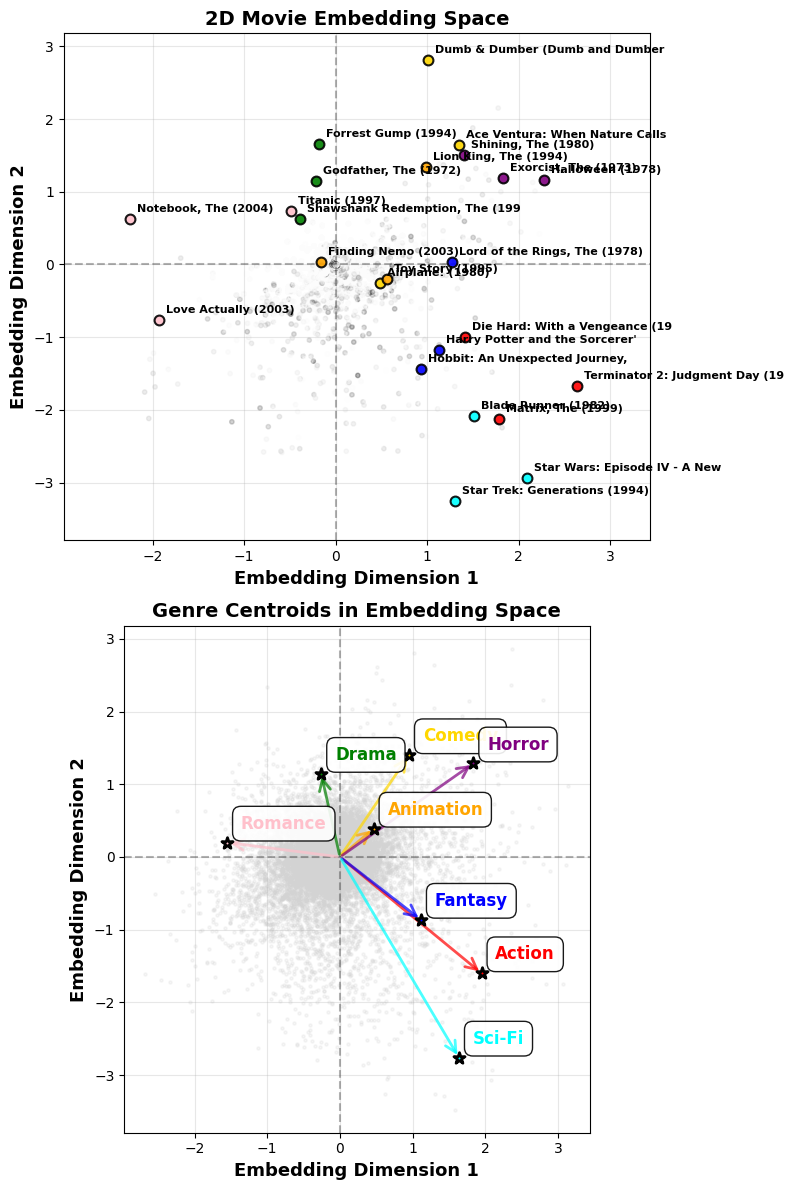

In [ ]:
print("Visualizing embeddings...")

# Visualize
plot_2d_embeddings(
    item_vectors=item_vectors_2d,
    item_biases=item_biases_2d,
    selected_movies_df=selected_movies,
    movie_rating_counts=movie_rating_counts,
    idx_to_movieid=idx_to_movieid,
    save_path='2d_movie_embeddings.pdf'
)

In [ ]:
print("Analyzing geometry...")

# Analyze
analyze_embedding_geometry(selected_movies)

Analyzing geometry...

EMBEDDING GEOMETRY ANALYSIS

Distance Analysis:
  Within-genre distance (avg):  1.340
  Between-genre distance (avg): 2.308
  Separation ratio:             1.72x
GOOD CLUSTERING: Genres well-separated in embedding space
MOST OPPOSITE MOVIE PAIRS (furthest apart):
              movie1                         movie2  genre1  genre2  distance
 Blade Runner (1982) Hobbit: An Unexpected Journey,  Sci-Fi Fantasy  4.730036
Notebook, The (2004)  Star Trek: Generations (1994) Romance  Sci-Fi  4.533449
    Airplane! (1980) Hobbit: An Unexpected Journey,  Comedy Fantasy  4.509122
Notebook, The (2004)            Blade Runner (1982) Romance  Sci-Fi  4.364642
 Shining, The (1980) Hobbit: An Unexpected Journey,  Horror Fantasy  4.321978
